In [1]:

import sys
import pandas as pd
import sklearn
import geopandas as gpd

print("Python:", sys.version.split()[0])
print("Interpreter:", sys.executable)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("GeoPandas:", gpd.__version__)


Python: 3.12.2
Interpreter: d:\Purity\GitHub-Repository\africa-ai-readiness-investment-intelligence\.venv\Scripts\python.exe
Pandas: 3.1.1
Scikit-learn: 1.9.1
GeoPandas: 1.2.0


### data paths

In [2]:

from pathlib import Path

# Project root: one level above the notebooks folder
PROJECT_ROOT = Path.cwd().resolve().parent

print("Current working directory:", Path.cwd())
print("Project root:", PROJECT_ROOT)

# Locate the GHSL Excel workbooks
print("\nNext: identify the GHSL workbook locations.")


Current working directory: d:\Purity\GitHub-Repository\africa-ai-readiness-investment-intelligence\notebooks
Project root: D:\Purity\GitHub-Repository\africa-ai-readiness-investment-intelligence

Next: identify the GHSL workbook locations.


### Locate the GHSL data

In [3]:

# Locate the raw GHSL Excel files
RAW_DIR = PROJECT_ROOT / "data" / "raw"

excel_files = sorted(
    list(RAW_DIR.glob("*.xlsx")) +
    list(RAW_DIR.glob("*.xls"))
)

print("Raw data directory:", RAW_DIR)
print("Number of Excel files:", len(excel_files))

for file in excel_files:
    print(f" - {file.name}")


Raw data directory: D:\Purity\GitHub-Repository\africa-ai-readiness-investment-intelligence\data\raw
Number of Excel files: 2
 - GHS_UCDB_REGION_NORTHERN_AFRICA_AND_WESTERN_ASIA_R2024A.xlsx
 - GHS_UCDB_REGION_SUB_SAHARAN_AFRICA_R2024A.xlsx


### Inspect the worksheets

In [4]:

# Inspect workbook structure without loading the datasets
import pandas as pd

for file in excel_files:
    workbook = pd.ExcelFile(file)

    print(f"\nWorkbook: {file.name}")
    print("Number of sheets:", len(workbook.sheet_names))
    print("Sheets:", workbook.sheet_names)



Workbook: GHS_UCDB_REGION_NORTHERN_AFRICA_AND_WESTERN_ASIA_R2024A.xlsx
Number of sheets: 17
Sheets: ['Description', 'Index', 'GENERAL_CHARACTERISTICS', 'GHSL', 'CLIMATE', 'EMISSIONS', 'EXPOSURE', 'GEOGRAPHY', 'GREENNESS', 'HAZARD_RISK', 'HEALTH', 'INFRASTRUCTURES', 'LULC', 'NATURAL_SYSTEMS', 'SDG', 'SOCIOECONOMIC', 'WATER']

Workbook: GHS_UCDB_REGION_SUB_SAHARAN_AFRICA_R2024A.xlsx
Number of sheets: 17
Sheets: ['Description', 'Index', 'GENERAL_CHARACTERISTICS', 'GHSL', 'CLIMATE', 'EMISSIONS', 'EXPOSURE', 'GEOGRAPHY', 'GREENNESS', 'HAZARD_RISK', 'HEALTH', 'INFRASTRUCTURES', 'LULC', 'NATURAL_SYSTEMS', 'SDG', 'SOCIOECONOMIC', 'WATER']


In [5]:

# Preview the first five rows of the GHSL general characteristics

for file in excel_files:
    df_preview = pd.read_excel(
        file,
        sheet_name="GENERAL_CHARACTERISTICS",
        nrows=5
    )

    print(f"\nWorkbook: {file.name}")
    print("Shape:", df_preview.shape)
    print("Columns:", df_preview.columns.tolist())

    display(df_preview.head())



Workbook: GHS_UCDB_REGION_NORTHERN_AFRICA_AND_WESTERN_ASIA_R2024A.xlsx
Shape: (5, 13)
Columns: ['ID_UC_G0', 'GC_UCN_MAI_2025', 'GC_UCN_LIS_2025', 'GC_CNT_GAD_2025', 'GC_CNT_UNN_2025', 'GC_UCA_KM2_2025', 'GC_POP_TOT_2025', 'GC_DEV_WIG_2025', 'GC_DEV_USR_2025', 'GC_PLS_SCR_2025', 'GC_UCB_YOB_2025', 'GC_UCB_YOD_2025', 'GC_UCM_CAP']


,ID_UC_G0,GC_UCN_MAI_2025,GC_UCN_LIS_2025,GC_CNT_GAD_2025,GC_CNT_UNN_2025,GC_UCA_KM2_2025,GC_POP_TOT_2025,GC_DEV_WIG_2025,GC_DEV_USR_2025,GC_PLS_SCR_2025,GC_UCB_YOB_2025,GC_UCB_YOD_2025,GC_UCM_CAP
0,45,Dakhla,Dakhla,Western Sahara,Western Sahara,33,180740.47580,NaN,Northern Africa and Western Asia,High,2005,2030,0
1,58,Bechar,Bechar,Algeria,Algeria,30,200687.22400,Lower Middle,Northern Africa and Western Asia,High,1985,2030,0
2,74,Al-Kaf,Al-Kaf,Tunisia,Tunisia,11,50808.68934,Lower Middle,Northern Africa and Western Asia,High,2000,2025,0
3,81,Al Zawiyah,Al Zawiyah; Surman,Libya,Libya,115,210856.64570,Upper Middle,Northern Africa and Western Asia,High,2000,2030,0
4,111,El Geneina,El Geneina,Sudan,Sudan,23,164688.11840,Low income,Northern Africa and Western Asia,High,1975,2030,0



Workbook: GHS_UCDB_REGION_SUB_SAHARAN_AFRICA_R2024A.xlsx
Shape: (5, 13)
Columns: ['ID_UC_G0', 'GC_UCN_MAI_2025', 'GC_UCN_LIS_2025', 'GC_CNT_GAD_2025', 'GC_CNT_UNN_2025', 'GC_UCA_KM2_2025', 'GC_POP_TOT_2025', 'GC_DEV_WIG_2025', 'GC_DEV_USR_2025', 'GC_PLS_SCR_2025', 'GC_UCB_YOB_2025', 'GC_UCB_YOD_2025', 'GC_UCM_CAP']


,ID_UC_G0,GC_UCN_MAI_2025,GC_UCN_LIS_2025,GC_CNT_GAD_2025,GC_CNT_UNN_2025,GC_UCA_KM2_2025,GC_POP_TOT_2025,GC_DEV_WIG_2025,GC_DEV_USR_2025,GC_PLS_SCR_2025,GC_UCB_YOB_2025,GC_UCB_YOD_2025,GC_UCM_CAP
0,38,Mindelo,Mindelo,Cabo Verde,Cabo Verde,18,8.827388e+04,Lower Middle,Sub-Saharan Africa,High,2000,2030,0
1,39,Dakar,Dakar; GuÃ©diawaye; Pikine; Rufisque,Senegal,Senegal,277,3.970202e+06,Lower Middle,Sub-Saharan Africa,High,1975,2030,1
2,40,Serrekunda,Serrekunda,Gambia,Gambia,181,1.313465e+06,Low income,Sub-Saharan Africa,High,1975,2030,0
3,41,Nouadhibou,Nouadhibou,Mauritania,Mauritania,38,1.774690e+05,Lower Middle,Sub-Saharan Africa,High,1995,2030,0
4,43,Bissau,Bissau,Guinea-Bissau,Guinea-Bissau,83,6.744443e+05,Low income,Sub-Saharan Africa,High,1975,2030,1


### Establish the African urban-centre universe

In [6]:

# Load general characteristics for both regions

ssa_file = next(
    f for f in excel_files
    if "SUB_SAHARAN_AFRICA" in f.name.upper()
)

north_file = next(
    f for f in excel_files
    if "NORTHERN_AFRICA" in f.name.upper()
)

ssa = pd.read_excel(
    ssa_file,
    sheet_name="GENERAL_CHARACTERISTICS"
)

north_west = pd.read_excel(
    north_file,
    sheet_name="GENERAL_CHARACTERISTICS"
)

print("Sub-Saharan Africa:", len(ssa))
print("Northern Africa + Western Asia:", len(north_west))

# Examine the countries in the combined northern region
country_counts = (
    north_west["GC_CNT_UNN_2025"]
    .value_counts()
    .sort_index()
)

display(country_counts)


Sub-Saharan Africa: 1658
Northern Africa + Western Asia: 1038


GC_CNT_UNN_2025
Algeria                 109
Armenia                   2
Azerbaijan               20
Bahrain                   1
Cyprus                    5
Egypt                   214
Georgia                   3
Iraq                     86
Israel                   22
Jordan                   16
Kuwait                    3
Lebanon                   8
Libya                    13
Morocco                  72
Oman                      9
Qatar                     4
Saudi Arabia             45
State of Palestine       14
Sudan                    80
Syrian Arab Republic     39
Tunisia                  24
Turkey                  174
United Arab Emirates     15
Western Sahara            2
Yemen                    58
Name: count, dtype: int64

### Filter Northern Africa and combine the African urban centres

In [7]:

# Northern African countries/territories in the GHSL dataset
north_africa_countries = [
    "Algeria",
    "Egypt",
    "Libya",
    "Morocco",
    "Sudan",
    "Tunisia",
    "Western Sahara"
]

# Retain Northern African observations only
north_africa = north_west[
    north_west["GC_CNT_UNN_2025"].isin(north_africa_countries)
].copy()

# Combine with Sub-Saharan Africa
africa_cities = pd.concat(
    [ssa, north_africa],
    ignore_index=True
)

# Verify observation counts
print("Sub-Saharan Africa:", len(ssa))
print("Northern Africa:", len(north_africa))
print("Total African urban centres:", len(africa_cities))

# Verify unique urban-centre identifiers
print("Unique urban-centre IDs:",
      africa_cities["ID_UC_G0"].nunique())

print("Duplicate IDs:",
      africa_cities["ID_UC_G0"].duplicated().sum())

# Verify country coverage
print("Countries/territories:",
      africa_cities["GC_CNT_UNN_2025"].nunique())


Sub-Saharan Africa: 1658
Northern Africa: 514
Total African urban centres: 2172
Unique urban-centre IDs: 2172
Duplicate IDs: 0
Countries/territories: 56


### Verify urban-centre identifiers across GHSL worksheets

In [8]:

# Check identifiers and worksheet dimensions

sheets_to_check = [
    "GHSL",
    "INFRASTRUCTURES",
    "SOCIOECONOMIC",
    "CLIMATE",
    "HAZARD_RISK",
    "WATER"
]

for sheet in sheets_to_check:
    preview = pd.read_excel(
        ssa_file,
        sheet_name=sheet,
        nrows=5
    )

    print(f"\n{sheet}")
    print("Columns:", len(preview.columns))
    print("First five column names:", preview.columns[:5].tolist())
    print("ID_UC_G0 present:", "ID_UC_G0" in preview.columns)



GHSL
Columns: 551
First five column names: ['ID_UC_G0', 'GC_UCN_MAI_2025', 'GC_CNT_GAD_2025', 'GC_UCA_KM2_2025', 'GC_POP_TOT_2025']
ID_UC_G0 present: True

INFRASTRUCTURES
Columns: 17
First five column names: ['ID_UC_G0', 'GC_UCN_MAI_2025', 'GC_CNT_GAD_2025', 'GC_UCA_KM2_2025', 'GC_POP_TOT_2025']
ID_UC_G0 present: True

SOCIOECONOMIC
Columns: 183
First five column names: ['ID_UC_G0', 'GC_UCN_MAI_2025', 'GC_CNT_GAD_2025', 'GC_UCA_KM2_2025', 'GC_POP_TOT_2025']
ID_UC_G0 present: True

CLIMATE
Columns: 109
First five column names: ['ID_UC_G0', 'GC_UCN_MAI_2025', 'GC_CNT_GAD_2025', 'GC_UCA_KM2_2025', 'GC_POP_TOT_2025']
ID_UC_G0 present: True

HAZARD_RISK
Columns: 118
First five column names: ['ID_UC_G0', 'GC_UCN_MAI_2025', 'GC_CNT_GAD_2025', 'GC_UCA_KM2_2025', 'GC_POP_TOT_2025']
ID_UC_G0 present: True

WATER
Columns: 28
First five column names: ['ID_UC_G0', 'GC_UCN_MAI_2025', 'GC_CNT_GAD_2025', 'GC_UCA_KM2_2025', 'GC_POP_TOT_2025']
ID_UC_G0 present: True


### Verify urban-centre ID integrity across GHSL worksheets before joining

In [9]:
# Check identifier integrity in both regional workbooks

for file in excel_files:
    print(f"\nWorkbook: {file.name}")

    for sheet in sheets_to_check:
        ids = pd.read_excel(
            file,
            sheet_name=sheet,
            usecols=["ID_UC_G0"]
        )

        print(
            f"{sheet}: "
            f"rows={len(ids)}, "
            f"unique IDs={ids['ID_UC_G0'].nunique()}, "
            f"duplicates={ids['ID_UC_G0'].duplicated().sum()}, "
            f"missing IDs={ids['ID_UC_G0'].isna().sum()}"
        )


Workbook: GHS_UCDB_REGION_NORTHERN_AFRICA_AND_WESTERN_ASIA_R2024A.xlsx
GHSL: rows=1038, unique IDs=1038, duplicates=0, missing IDs=0
INFRASTRUCTURES: rows=1038, unique IDs=1038, duplicates=0, missing IDs=0
SOCIOECONOMIC: rows=1038, unique IDs=1038, duplicates=0, missing IDs=0
CLIMATE: rows=1038, unique IDs=1038, duplicates=0, missing IDs=0
HAZARD_RISK: rows=1038, unique IDs=1038, duplicates=0, missing IDs=0
WATER: rows=1038, unique IDs=1038, duplicates=0, missing IDs=0

Workbook: GHS_UCDB_REGION_SUB_SAHARAN_AFRICA_R2024A.xlsx
GHSL: rows=1658, unique IDs=1658, duplicates=0, missing IDs=0
INFRASTRUCTURES: rows=1658, unique IDs=1658, duplicates=0, missing IDs=0
SOCIOECONOMIC: rows=1658, unique IDs=1658, duplicates=0, missing IDs=0
CLIMATE: rows=1658, unique IDs=1658, duplicates=0, missing IDs=0
HAZARD_RISK: rows=1658, unique IDs=1658, duplicates=0, missing IDs=0
WATER: rows=1658, unique IDs=1658, duplicates=0, missing IDs=0


### Verify consistent urban-centre IDs across worksheets

In [10]:
# Compare each worksheet's IDs with GENERAL_CHARACTERISTICS

for file in excel_files:
    print(f"\nWorkbook: {file.name}")

    reference = set(
        pd.read_excel(
            file,
            sheet_name="GENERAL_CHARACTERISTICS",
            usecols=["ID_UC_G0"]
        )["ID_UC_G0"]
    )

    for sheet in sheets_to_check:
        sheet_ids = set(
            pd.read_excel(
                file,
                sheet_name=sheet,
                usecols=["ID_UC_G0"]
            )["ID_UC_G0"]
        )

        print(
            f"{sheet}: "
            f"missing from sheet={len(reference - sheet_ids)}, "
            f"extra in sheet={len(sheet_ids - reference)}"
        )


Workbook: GHS_UCDB_REGION_NORTHERN_AFRICA_AND_WESTERN_ASIA_R2024A.xlsx
GHSL: missing from sheet=0, extra in sheet=0
INFRASTRUCTURES: missing from sheet=0, extra in sheet=0
SOCIOECONOMIC: missing from sheet=0, extra in sheet=0
CLIMATE: missing from sheet=0, extra in sheet=0
HAZARD_RISK: missing from sheet=0, extra in sheet=0
WATER: missing from sheet=0, extra in sheet=0

Workbook: GHS_UCDB_REGION_SUB_SAHARAN_AFRICA_R2024A.xlsx
GHSL: missing from sheet=0, extra in sheet=0
INFRASTRUCTURES: missing from sheet=0, extra in sheet=0
SOCIOECONOMIC: missing from sheet=0, extra in sheet=0
CLIMATE: missing from sheet=0, extra in sheet=0
HAZARD_RISK: missing from sheet=0, extra in sheet=0
WATER: missing from sheet=0, extra in sheet=0


### Build the analytical dataset

##### ### Extract Candidate GHSL Indicators

This step identifies 11 candidate predictors across four GHSL thematic worksheets: population, infrastructure, socioeconomic conditions, and climate. The indicators represent key dimensions of sustainable AI infrastructure readiness in African urban centres.

Before extraction, we verify that all selected variables exist in both regional datasets. These are preliminary candidates; their completeness, variability, relevance, and redundancy will be assessed before final feature selection and clustering.

In [11]:
# Candidate indicators grouped by GHSL worksheet

candidate_columns = {
    "GHSL": [
        "GH_POP_TOT_2025"
    ],
    "INFRASTRUCTURES": [
        "IN_CIS_ENE_2020",
        "IN_CIS_TEL_2020",
        "IN_CIS_TRA_2020",
        "IN_CIS_EDU_2020",
        "IN_CIS_WAT_2020",
        "IN_ROA_DEN_2024"
    ],
    "SOCIOECONOMIC": [
        "SC_GDP_AVG_2020",
        "SC_SEC_SYT_2020"
    ],
    "CLIMATE": [
        "CL_REN_PVO_2020",
        "CL_B01_CUR_2010"
    ]
}

# Check that every candidate column exists
# in both regional workbooks

for file in excel_files:
    print(f"\nWorkbook: {file.name}")

    for sheet, columns in candidate_columns.items():

        available = pd.read_excel(
            file,
            sheet_name=sheet,
            nrows=0
        ).columns

        missing = [
            col for col in columns
            if col not in available
        ]

        print(
            f"{sheet}: "
            f"{len(columns)} requested, "
            f"{len(missing)} missing"
        )

        if missing:
            print("Missing columns:", missing)


Workbook: GHS_UCDB_REGION_NORTHERN_AFRICA_AND_WESTERN_ASIA_R2024A.xlsx
GHSL: 1 requested, 0 missing
INFRASTRUCTURES: 6 requested, 0 missing
SOCIOECONOMIC: 2 requested, 0 missing
CLIMATE: 2 requested, 0 missing

Workbook: GHS_UCDB_REGION_SUB_SAHARAN_AFRICA_R2024A.xlsx
GHSL: 1 requested, 0 missing
INFRASTRUCTURES: 6 requested, 0 missing
SOCIOECONOMIC: 2 requested, 0 missing
CLIMATE: 2 requested, 0 missing


### Extract and merge the indicators

**Extract and merge candidate indicators.** 
The selected indicators are extracted from their respective GHSL worksheets and merged using the unique urban-centre identifier (ID_UC_G0). The resulting dataset will contain one observation per African urban centre. Row counts and identifier uniqueness are checked after merging to detect unintended observation losses or duplication.

In [12]:
# Start with our verified African urban-centre dataset
df_analytical = africa_cities.copy()

df_analytical = df_analytical.drop(
    columns=["GH_POP_TOT_2025"],
    errors="ignore"
)

initial_rows = len(df_analytical)

# Extract and merge indicators from both regional workbooks
for sheet, columns in candidate_columns.items():

    regional_data = []

    for file in excel_files:

        df = pd.read_excel(
            file,
            sheet_name=sheet,
            usecols=["ID_UC_G0"] + columns
        )

        regional_data.append(df)

    # Combine both regional datasets
    df_sheet = pd.concat(
        regional_data,
        ignore_index=True
    )

    # Keep only the African urban centres
    df_sheet = df_sheet[
        df_sheet["ID_UC_G0"].isin(
            df_analytical["ID_UC_G0"]
        )
    ]

    # Confirm identifiers are unique before merging
    assert df_sheet["ID_UC_G0"].is_unique, (
        f"Duplicate IDs found in {sheet}"
    )

    # Merge indicators
    df_analytical = df_analytical.merge(
        df_sheet,
        on="ID_UC_G0",
        how="left",
        validate="one_to_one"
    )

    print(
        f"{sheet}: "
        f"{len(df_analytical)} observations"
    )

# Final integrity checks
assert len(df_analytical) == initial_rows
assert df_analytical["ID_UC_G0"].is_unique

print("\nFinal analytical dataset:")
print("Observations:", len(df_analytical))
print("Columns:", len(df_analytical.columns))
print("Duplicate IDs:", df_analytical["ID_UC_G0"].duplicated().sum())

display(df_analytical.head())

GHSL: 2172 observations
INFRASTRUCTURES: 2172 observations
SOCIOECONOMIC: 2172 observations
CLIMATE: 2172 observations

Final analytical dataset:
Observations: 2172
Columns: 24
Duplicate IDs: 0


,ID_UC_G0,GC_UCN_MAI_2025,GC_UCN_LIS_2025,GC_CNT_GAD_2025,GC_CNT_UNN_2025,GC_UCA_KM2_2025,GC_POP_TOT_2025,GC_DEV_WIG_2025,GC_DEV_USR_2025,GC_PLS_SCR_2025,...,IN_CIS_ENE_2020,IN_CIS_TRA_2020,IN_CIS_WAT_2020,IN_CIS_TEL_2020,IN_CIS_EDU_2020,IN_ROA_DEN_2024,SC_GDP_AVG_2020,SC_SEC_SYT_2020,CL_B01_CUR_2010,CL_REN_PVO_2020
0,38,Mindelo,Mindelo,Cabo Verde,Cabo Verde,18,8.827388e+04,Lower Middle,Sub-Saharan Africa,High,...,2.620000e-08,0.002402,6.260000e-09,2.460000e-07,0.000719,0.013276,24662104.38,6.713000,23.108,NaN
1,39,Dakar,Dakar; GuÃ©diawaye; Pikine; Rufisque,Senegal,Senegal,277,3.970202e+06,Lower Middle,Sub-Saharan Africa,High,...,2.131755e-02,0.038976,1.617000e-04,1.385724e-03,0.020982,0.020983,62829932.16,5.047000,24.496,4.747
2,40,Serrekunda,Serrekunda,Gambia,Gambia,181,1.313465e+06,Low income,Sub-Saharan Africa,High,...,4.863860e-04,0.012696,5.970000e-05,1.402762e-03,0.004661,0.014302,13591185.78,5.764927,25.180,4.672
3,41,Nouadhibou,Nouadhibou,Mauritania,Mauritania,38,1.774690e+05,Lower Middle,Sub-Saharan Africa,High,...,1.800000e-05,0.006597,3.690000e-06,5.439420e-04,0.000048,0.011540,28353481.96,9.137000,20.147,5.101
4,43,Bissau,Bissau,Guinea-Bissau,Guinea-Bissau,83,6.744443e+05,Low income,Sub-Saharan Africa,High,...,0.000000e+00,0.006249,0.000000e+00,2.830000e-06,0.000695,0.008329,18002209.03,6.934985,26.630,4.519


### Missing-value assessment

**Assess missing values in candidate indicators**
Evaluate the completeness of each candidate indicator across the 2,172 African urban centres. Calculate missing counts and percentages to identify variables that could reduce the usable sample size during subsequent analysis.

In [13]:
# Assess missing values in candidate indicators

indicator_columns = [
    col
    for columns in candidate_columns.values()
    for col in columns
]

missing_summary = pd.DataFrame({
    "Missing": df_analytical[indicator_columns].isna().sum(),
    "Available": df_analytical[indicator_columns].notna().sum(),
    "Missing (%)": (
        df_analytical[indicator_columns].isna().mean() * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    "Missing (%)",
    ascending=False
)

display(missing_summary)

print(
    "Complete observations across all candidate indicators:",
    df_analytical[indicator_columns].dropna().shape[0]
)

,Missing,Available,Missing (%)
IN_ROA_DEN_2024,1,2171,0.05
CL_REN_PVO_2020,1,2171,0.05
GH_POP_TOT_2025,0,2172,0.00
IN_CIS_TEL_2020,0,2172,0.00
IN_CIS_ENE_2020,0,2172,0.00
IN_CIS_EDU_2020,0,2172,0.00
IN_CIS_TRA_2020,0,2172,0.00
IN_CIS_WAT_2020,0,2172,0.00
SC_GDP_AVG_2020,0,2172,0.00
SC_SEC_SYT_2020,0,2172,0.00


Complete observations across all candidate indicators: 2170


### Identify urban centres with missing candidate indicators

In [14]:
# Identify urban centres with missing candidate indicators

incomplete_cities = df_analytical.loc[
    df_analytical[indicator_columns].isna().any(axis=1),
    ["GC_UCN_MAI_2025", "GC_CNT_UNN_2025"] + indicator_columns
]

display(incomplete_cities)

,GC_UCN_MAI_2025,GC_CNT_UNN_2025,GH_POP_TOT_2025,IN_CIS_ENE_2020,IN_CIS_TEL_2020,IN_CIS_TRA_2020,IN_CIS_EDU_2020,IN_CIS_WAT_2020,IN_ROA_DEN_2024,SC_GDP_AVG_2020,SC_SEC_SYT_2020,CL_REN_PVO_2020,CL_B01_CUR_2010
0,Mindelo,Cabo Verde,88273.87923,2.620000e-08,2.460000e-07,0.002402,0.000719,6.260000e-09,0.013276,2.466210e+07,6.713,NaN,23.108
754,Muala,Mozambique,70976.33067,3.311835e-03,1.199490e-04,0.003404,0.000626,0.000000e+00,NaN,3.411205e+06,2.793,4.578,22.775


In [16]:
# Show only the missing indicators for each affected city

for _, city in incomplete_cities.iterrows():
    missing = city[indicator_columns][
        city[indicator_columns].isna()
    ].index.tolist()

    print(
        f"{city['GC_UCN_MAI_2025']} "
        f"({city['GC_CNT_UNN_2025']}): {missing}"
    )

Mindelo (Cabo Verde): ['CL_REN_PVO_2020']
Muala (Mozambique): ['IN_ROA_DEN_2024']


### Missing-data assessment — preliminary findings

The analytical dataset contains 2,172 African urban centres and 11 candidate indicators. Nine indicators have complete coverage, while solar PV potential and road density each have one missing value, affecting Mindelo (Cabo Verde) and Muala (Mozambique), respectively.

Complete-case analysis would retain 2,170 observations (99.91%). Both affected urban centres are retained pending final feature selection and missing-data treatment.

### Descriptive statistics of candidate indicators

This analysis examines the distribution and variability of the 11 candidate indicators across African urban centres. Summary statistics are used to identify differences in scale, skewness, extreme values and potential data-quality concerns before feature selection and clustering.

In [17]:

# Descriptive statistics for the 11 candidate indicators

descriptive_stats = df_analytical[indicator_columns].describe().T

# Add skewness to assess asymmetry
descriptive_stats["skewness"] = (
    df_analytical[indicator_columns].skew()
)

# Round values for easier inspection
display(descriptive_stats.round(3))


,count,mean,std,min,25%,50%,75%,max,skewness
GH_POP_TOT_2025,2172.0,2.873367e+05,9.662781e+05,50007.746,67677.480,1.011437e+05,1.913242e+05,2.523032e+07,13.113
IN_CIS_ENE_2020,2172.0,1.200000e-02,1.800000e-02,0.000,0.000,5.000000e-03,1.800000e-02,1.330000e-01,1.953
IN_CIS_TEL_2020,2172.0,0.000000e+00,1.000000e-03,0.000,0.000,0.000000e+00,0.000000e+00,1.500000e-02,5.454
IN_CIS_TRA_2020,2172.0,8.000000e-03,9.000000e-03,0.000,0.003,5.000000e-03,1.100000e-02,8.600000e-02,3.017
IN_CIS_EDU_2020,2172.0,2.000000e-03,5.000000e-03,0.000,0.000,0.000000e+00,2.000000e-03,8.400000e-02,6.765
IN_CIS_WAT_2020,2172.0,0.000000e+00,6.000000e-03,0.000,0.000,0.000000e+00,0.000000e+00,1.460000e-01,22.260
IN_ROA_DEN_2024,2171.0,1.000000e-02,5.000000e-03,0.000,0.006,9.000000e-03,1.300000e-02,3.200000e-02,0.420
SC_GDP_AVG_2020,2172.0,2.170678e+07,2.060273e+07,575327.583,9078069.288,1.552954e+07,2.632614e+07,2.267162e+08,3.000
SC_SEC_SYT_2020,2172.0,6.077000e+00,2.900000e+00,0.330,3.353,6.286000e+00,8.446000e+00,1.378200e+01,0.084
CL_REN_PVO_2020,2171.0,4.496000e+00,4.500000e-01,3.352,4.167,4.588000e+00,4.823000e+00,5.452000e+00,-0.427


### Distribution analysis of candidate indicators

Histograms are used to examine the distribution, skewness, concentration and extreme values of the 11 candidate indicators. The results will inform subsequent decisions about transformations, scaling and feature selection for clustering.

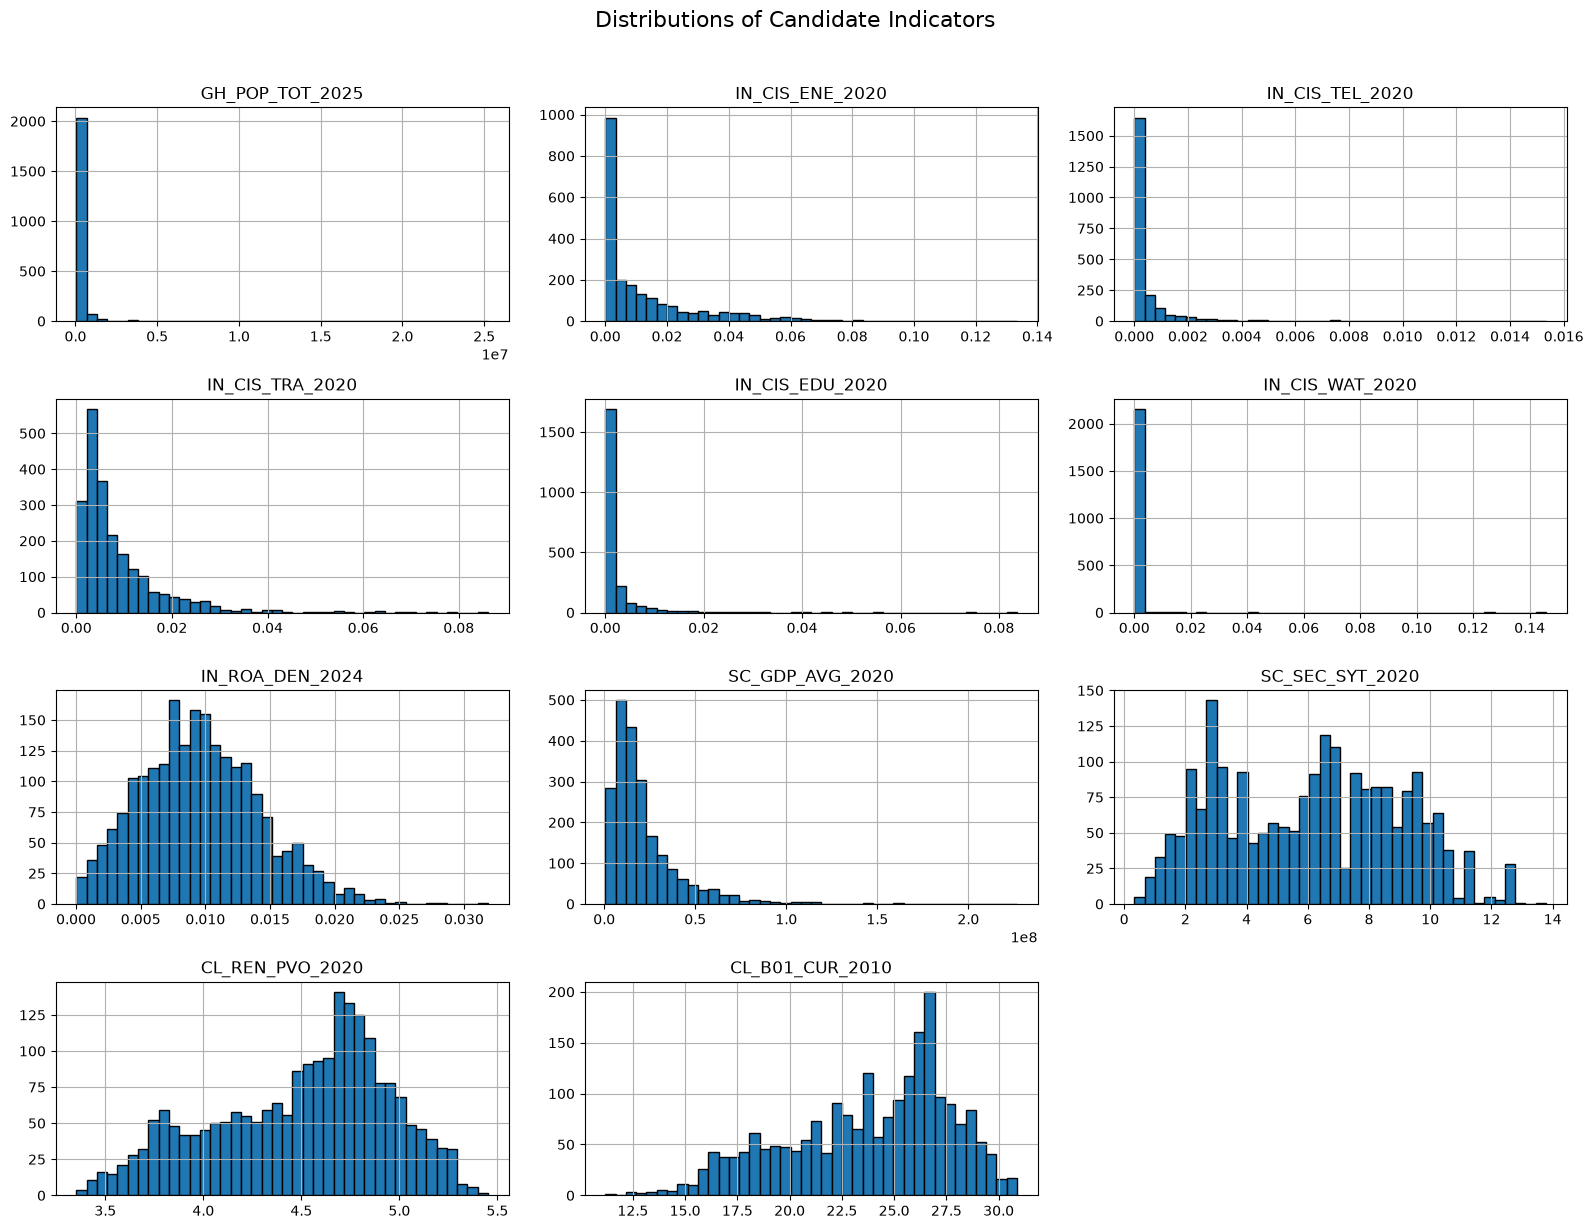

In [18]:

# Visualize distributions of candidate indicators

import matplotlib.pyplot as plt

df_analytical[indicator_columns].hist(
    bins=40,
    figsize=(16, 12),
    layout=(4, 3),
    edgecolor="black"
)

plt.suptitle(
    "Distributions of Candidate Indicators",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()



### Histogram Interpretation of Candidate GHSL Indicators

The table summarizes the distribution patterns of the 11 candidate indicators across 2,172 African urban centres. Preliminary decisions identify variables requiring further investigation or potential transformation before clustering.

| Graph position | GHSL indicator code | Indicator | Distribution | Preliminary decision |
|---|---|---|---|---|
| Row 1, left | `GH_POP_TOT_2025` | Population | Extremely right-skewed | Consider log transformation |
| Row 1, middle | `IN_CIS_ENE_2020` | Energy infrastructure | Right-skewed | Investigate |
| Row 1, right | `IN_CIS_TEL_2020` | Telecommunications | Strong concentration near zero | Investigate |
| Row 2, left | `IN_CIS_TRA_2020` | Transport infrastructure | Right-skewed | Consider transformation |
| Row 2, middle | `IN_CIS_EDU_2020` | Education infrastructure | Concentrated near zero | Investigate |
| Row 2, right | `IN_CIS_WAT_2020` | Water infrastructure | Extremely concentrated near zero | Examine carefully |
| Row 3, left | `IN_ROA_DEN_2024` | Road density | Relatively balanced, slight right tail | Likely retain unchanged |
| Row 3, middle | `SC_GDP_AVG_2020` | Average GDP | Strong right-skew | Consider log transformation |
| Row 3, right | `SC_SEC_SYT_2020` | Mean years of schooling | Multimodal | Retain for investigation |
| Row 4, left | `CL_REN_PVO_2020` | Solar PV potential | Broad, uneven distribution | Likely retain unchanged |
| Row 4, middle | `CL_B01_CUR_2010` | Annual mean temperature | Broad, asymmetric distribution | Likely retain unchanged |

**Methodological note:** These interpretations are preliminary and based on the original, untransformed distributions. No indicators or observations have been excluded. Further assessment of zero values, outliers, correlations and feature redundancy will inform feature selection and preprocessing. Variables retained without distribution transformation may still require scaling before distance-based clustering.


### Prepare GHSL urban-centre coordinates for ITU fibre proximity analysis

In [19]:
# Identify available geographic coordinate columns

coordinate_candidates = [
    col for col in df_analytical.columns
    if any(term in col.lower()
           for term in ["lat", "lon", "long", "centroid", "coord", "x_", "y_"])
]

print("Potential coordinate columns:")
print(coordinate_candidates)

Potential coordinate columns:
[]


### Check whether coordinates are present in GHSL dataset

In [20]:
# Inspect original GHSL general characteristics columns

for file in excel_files:
    df_check = pd.read_excel(
        file,
        sheet_name="GENERAL_CHARACTERISTICS",
        nrows=3
    )

    print(f"\nFile: {file}")
    print("Available columns:")
    print(df_check.columns.tolist())


File: D:\Purity\GitHub-Repository\africa-ai-readiness-investment-intelligence\data\raw\GHS_UCDB_REGION_NORTHERN_AFRICA_AND_WESTERN_ASIA_R2024A.xlsx
Available columns:
['ID_UC_G0', 'GC_UCN_MAI_2025', 'GC_UCN_LIS_2025', 'GC_CNT_GAD_2025', 'GC_CNT_UNN_2025', 'GC_UCA_KM2_2025', 'GC_POP_TOT_2025', 'GC_DEV_WIG_2025', 'GC_DEV_USR_2025', 'GC_PLS_SCR_2025', 'GC_UCB_YOB_2025', 'GC_UCB_YOD_2025', 'GC_UCM_CAP']

File: D:\Purity\GitHub-Repository\africa-ai-readiness-investment-intelligence\data\raw\GHS_UCDB_REGION_SUB_SAHARAN_AFRICA_R2024A.xlsx
Available columns:
['ID_UC_G0', 'GC_UCN_MAI_2025', 'GC_UCN_LIS_2025', 'GC_CNT_GAD_2025', 'GC_CNT_UNN_2025', 'GC_UCA_KM2_2025', 'GC_POP_TOT_2025', 'GC_DEV_WIG_2025', 'GC_DEV_USR_2025', 'GC_PLS_SCR_2025', 'GC_UCB_YOB_2025', 'GC_UCB_YOD_2025', 'GC_UCM_CAP']


### Search all GHSL worksheets for coordinates

In [21]:
# Search GHSL worksheets for geographic coordinate columns

search_terms = [
    "LAT", "LON", "LONG",
    "CENT", "COORD", "X_", "Y_"
]

for file in excel_files[:1]:
    print(f"\nChecking: {file.name}")

    workbook = pd.ExcelFile(file)

    for sheet in workbook.sheet_names:
        columns = pd.read_excel(
            file,
            sheet_name=sheet,
            nrows=0
        ).columns.tolist()

        matches = [
            col for col in columns
            if any(term in col.upper() for term in search_terms)
        ]

        if matches:
            print(f"\n{sheet}:")
            print(matches)


Checking: GHS_UCDB_REGION_NORTHERN_AFRICA_AND_WESTERN_ASIA_R2024A.xlsx

Description:
['GHS-UCDB R2024A - GHS Urban Centre Database 2025']

GHSL:
['GH_BUH_MAX_2020']

EMISSIONS:
['EM_NOX_AGR_1975', 'EM_NOX_AGR_1980', 'EM_NOX_AGR_1985', 'EM_NOX_AGR_1990', 'EM_NOX_AGR_1995', 'EM_NOX_AGR_2000', 'EM_NOX_AGR_2005', 'EM_NOX_AGR_2010', 'EM_NOX_AGR_2015', 'EM_NOX_AGR_2020', 'EM_NOX_AGR_2024', 'EM_NOX_ENE_1975', 'EM_NOX_ENE_1980', 'EM_NOX_ENE_1985', 'EM_NOX_ENE_1990', 'EM_NOX_ENE_1995', 'EM_NOX_ENE_2000', 'EM_NOX_ENE_2005', 'EM_NOX_ENE_2010', 'EM_NOX_ENE_2015', 'EM_NOX_ENE_2020', 'EM_NOX_ENE_2024', 'EM_NOX_IND_1975', 'EM_NOX_IND_1980', 'EM_NOX_IND_1985', 'EM_NOX_IND_1990', 'EM_NOX_IND_1995', 'EM_NOX_IND_2000', 'EM_NOX_IND_2005', 'EM_NOX_IND_2010', 'EM_NOX_IND_2015', 'EM_NOX_IND_2020', 'EM_NOX_IND_2024', 'EM_NOX_RES_1975', 'EM_NOX_RES_1980', 'EM_NOX_RES_1985', 'EM_NOX_RES_1990', 'EM_NOX_RES_1995', 'EM_NOX_RES_2000', 'EM_NOX_RES_2005', 'EM_NOX_RES_2010', 'EM_NOX_RES_2015', 'EM_NOX_RES_2020', 'EM_

### Preparing GHSL Urban-Centre Coordinates for ITU Fibre-Proximity Analysis

Extract longitude and latitude from the GHSL GeoPackage files for Sub-Saharan and Northern Africa. Merge the coordinates with the analytical dataset using `ID_UC_G0`, validate all 2,172 urban centres, and prepare a WGS84 CSV (`X`, `Y`) for upload to the ITU Fibre-Proximity API.

In [24]:

import sqlite3
import pandas as pd
from pathlib import Path

raw = Path("../data/raw")

files = [
    raw / "GHS_UCDB_REGION_SUB_SAHARAN_AFRICA_R2024A.gpkg",
    raw / "GHS_UCDB_REGION_NORTHERN_AFRICA_AND_WESTERN_ASIA_R2024A.gpkg"
]

centroids = []

for file in files:
    with sqlite3.connect(file) as con:
        df = pd.read_sql_query("""
            SELECT
                ID_UC_G0,
                GC_UCC_LON_2025 AS X,
                GC_UCC_LAT_2025 AS Y
            FROM UC_centroids
        """, con)
        centroids.append(df)

df_coordinates = (
    pd.concat(centroids, ignore_index=True)
    .drop_duplicates(subset="ID_UC_G0")
)

# Retain only urban centres in our analytical dataset
df_itu = df_analytical[["ID_UC_G0"]].merge(
    df_coordinates,
    on="ID_UC_G0",
    how="left",
    validate="one_to_one"
)

print("Urban centres:", len(df_itu))
print("Missing coordinates:", df_itu[["X", "Y"]].isna().any(axis=1).sum())
print(df_itu.head())


Urban centres: 2172
Missing coordinates: 0
   ID_UC_G0            X            Y
0        38 -2436599.789  2076115.058
1        39 -1707136.794  1815364.184
2        40 -1644109.635  1652019.946
3        41 -1636766.990  2568013.525
4        43 -1544056.039  1463348.022


### Convert the coordinates to WGS84

In [25]:
from pyproj import Transformer

transformer = Transformer.from_crs(
    "ESRI:54009",
    "EPSG:4326",
    always_xy=True
)

df_itu["X"], df_itu["Y"] = transformer.transform(
    df_itu["X"].to_numpy(),
    df_itu["Y"].to_numpy()
)

print(df_itu.head())
print("Missing coordinates:", df_itu[["X", "Y"]].isna().any(axis=1).sum())

   ID_UC_G0          X          Y
0        38 -24.982595  16.884833
1        39 -17.389242  14.744559
2        40 -16.686812  13.407970
3        41 -17.036314  20.948819
4        43 -15.613077  11.867644
Missing coordinates: 0


### Validate before exporting

In [26]:
print("Urban centres:", len(df_itu))

print("Longitude valid:",
      df_itu["X"].between(-180, 180).all())

print("Latitude valid:",
      df_itu["Y"].between(-90, 90).all())

Urban centres: 2172
Longitude valid: True
Latitude valid: True


### Prepare the five-city pilot

In [27]:
from pathlib import Path

output_dir = Path("../data/interim")
output_dir.mkdir(parents=True, exist_ok=True)

df_itu[["X", "Y"]].round(6).to_csv(
    output_dir / "itu_fibre_all_2172.csv",
    index=False
)

print("Saved 2,172 urban-centre coordinates.")

Saved 2,172 urban-centre coordinates.


### Find the city-name column

In [28]:
import pandas as pd

file = excel_files[0]

df_names = pd.read_excel(
    file,
    sheet_name="GENERAL_CHARACTERISTICS",
    nrows=5
)

print(df_names.columns.tolist())

['ID_UC_G0', 'GC_UCN_MAI_2025', 'GC_UCN_LIS_2025', 'GC_CNT_GAD_2025', 'GC_CNT_UNN_2025', 'GC_UCA_KM2_2025', 'GC_POP_TOT_2025', 'GC_DEV_WIG_2025', 'GC_DEV_USR_2025', 'GC_PLS_SCR_2025', 'GC_UCB_YOB_2025', 'GC_UCB_YOD_2025', 'GC_UCM_CAP']


### Identify the city-name attribute

In [29]:
name_columns = [
    col for col in df_names.columns
    if any(term in col.upper()
           for term in ["NAME", "NAM", "CITY", "UC_NM"])
]

print("Possible city-name columns:")
print(name_columns)

Possible city-name columns:
[]


### Find the five nearest GHSL urban centres

In [30]:
from math import radians, sin, cos, asin, sqrt

# Approximate city-centre coordinates (latitude, longitude)
pilot_cities = {
    "Nairobi": (-1.2864, 36.8172),
    "Lagos": (6.5244, 3.3792),
    "Cairo": (30.0444, 31.2357),
    "Johannesburg": (-26.2041, 28.0473),
    "Accra": (5.6037, -0.1870)
}

def haversine(lat1, lon1, lat2, lon2):
    R = 6371
    dlat = radians(lat2 - lat1)
    dlon = radians(lon2 - lon1)
    a = (
        sin(dlat / 2)**2
        + cos(radians(lat1)) * cos(radians(lat2))
        * sin(dlon / 2)**2
    )
    return 2 * R * asin(sqrt(a))

pilot_rows = []

for city, (lat, lon) in pilot_cities.items():
    distances = df_itu.apply(
        lambda row: haversine(lat, lon, row["Y"], row["X"]),
        axis=1
    )

    nearest = df_itu.loc[distances.idxmin()]

    pilot_rows.append({
        "City": city,
        "ID_UC_G0": nearest["ID_UC_G0"],
        "X": nearest["X"],
        "Y": nearest["Y"],
        "Distance_km": distances.min()
    })

df_pilot = pd.DataFrame(pilot_rows)

print(df_pilot.to_string(index=False))

        City  ID_UC_G0         X          Y  Distance_km
     Nairobi    1717.0 36.852498  -1.264602     4.612279
       Lagos    1289.0  3.309999   6.570321     9.193104
       Cairo    4605.0 31.255176  30.069037     3.319413
Johannesburg    3512.0 28.039233 -26.181698     2.617841
       Accra    3175.0 -0.213052   5.606647     2.901550


### Export the ITU pilot CSV

In [31]:
# Save the five-city pilot for ITU
pilot_file = output_dir / "itu_fibre_pilot_5cities.csv"

df_pilot[["X", "Y"]].round(6).to_csv(
    pilot_file,
    index=False
)

# Preserve city names and IDs for matching results
df_pilot.to_csv(
    output_dir / "itu_fibre_pilot_lookup.csv",
    index=False
)

print("Pilot CSV saved:", pilot_file)
print("Number of cities:", len(df_pilot))

Pilot CSV saved: ..\data\interim\itu_fibre_pilot_5cities.csv
Number of cities: 5


### ITU Fibre Proximity — Pilot 2: Secondary African Urban Centres

Assess variation in terrestrial fibre-node proximity across smaller and secondary urban centres before processing the full dataset of 2,172 African urban centres.

In [32]:
# Candidate cities for the second ITU pilot
pilot2_cities = {
    "Kitale, Kenya": (1.0167, 35.0000),
    "Garissa, Kenya": (-0.4532, 39.6461),
    "Tamale, Ghana": (9.4075, -0.8533),
    "Wa, Ghana": (10.0601, -2.5099),
    "Maradi, Niger": (13.5000, 7.1000),
    "Zinder, Niger": (13.8053, 8.9881),
    "Gulu, Uganda": (2.7746, 32.2990),
    "Morogoro, Tanzania": (-6.8278, 37.6591),
    "Toliara, Madagascar": (-23.3500, 43.6667),
    "Ouarzazate, Morocco": (30.9335, -6.9370)
}

pilot2_rows = []

for city, (lat, lon) in pilot2_cities.items():

    distances = df_itu.apply(
        lambda row: haversine(lat, lon, row["Y"], row["X"]),
        axis=1
    )

    nearest = df_itu.loc[distances.idxmin()]

    pilot2_rows.append({
        "City": city,
        "ID_UC_G0": nearest["ID_UC_G0"],
        "X": nearest["X"],
        "Y": nearest["Y"],
        "Match_distance_km": distances.min()
    })

df_pilot2 = pd.DataFrame(pilot2_rows)

print(df_pilot2.to_string(index=False))

               City  ID_UC_G0         X          Y  Match_distance_km
      Kitale, Kenya    1110.0 34.995197   1.031185           1.696867
     Garissa, Kenya    2963.0 39.649341  -0.449167           0.575299
      Tamale, Ghana    2558.0 -0.847686   9.414279           0.973359
          Wa, Ghana     397.0 -2.515865  10.057955           0.695268
      Maradi, Niger    2115.0  7.105582  13.507133           0.996652
      Zinder, Niger    2883.0  8.985867  13.810186           0.594452
       Gulu, Uganda    1618.0 32.297500   2.770197           0.517166
 Morogoro, Tanzania    3360.0 37.658568  -6.804863           2.551128
Toliara, Madagascar     145.0 43.678456 -23.348716           1.208574
Ouarzazate, Morocco    2619.0 -6.919642  30.931130           1.676440


### Export the second ITU pilot

In [33]:
# Export second pilot for ITU
pilot2_file = output_dir / "itu_fibre_pilot2_10cities.csv"

df_pilot2[["X", "Y"]].round(6).to_csv(
    pilot2_file,
    index=False
)

# Preserve the city names and GHSL IDs
df_pilot2.to_csv(
    output_dir / "itu_fibre_pilot2_lookup.csv",
    index=False
)

print("Pilot 2 CSV saved:", pilot2_file)
print("Number of cities:", len(df_pilot2))
print("Unique GHSL IDs:", df_pilot2["ID_UC_G0"].nunique())

Pilot 2 CSV saved: ..\data\interim\itu_fibre_pilot2_10cities.csv
Number of cities: 10
Unique GHSL IDs: 10


### ITU Fibre Proximity — Pilot 3: Infrastructure-Constrained Urban Centres

Select 20 smaller African urban centres with low telecommunications infrastructure scores to test the discriminatory power of ITU fibre-node proximity.

In [34]:
# Pilot 3: Data-driven selection of infrastructure-constrained cities

# Merge the analytical indicators with our validated coordinates
df_candidates = df_analytical.merge(
    df_itu,
    on="ID_UC_G0",
    how="inner",
    validate="one_to_one"
)

# Retain centres with valid population, telecom scores and coordinates
df_candidates = df_candidates.dropna(
    subset=[
        "GH_POP_TOT_2025",
        "IN_CIS_TEL_2020",
        "X",
        "Y"
    ]
)

# Focus on smaller urban centres
population_limit = df_candidates["GH_POP_TOT_2025"].quantile(0.25)

df_small = df_candidates[
    df_candidates["GH_POP_TOT_2025"] <= population_limit
].copy()

# Select the 20 lowest telecommunications infrastructure scores
df_pilot3 = (
    df_small
    .sort_values(
        ["IN_CIS_TEL_2020", "GH_POP_TOT_2025"]
    )
    .head(20)
    .copy()
)

# Display the selected centres
print("Population threshold:", round(population_limit))
print("Selected centres:", len(df_pilot3))
print("Unique GHSL IDs:", df_pilot3["ID_UC_G0"].nunique())

display(
    df_pilot3[
        [
            "ID_UC_G0",
            "GH_POP_TOT_2025",
            "IN_CIS_TEL_2020",
            "X",
            "Y"
        ]
    ]
)

Population threshold: 67677
Selected centres: 20
Unique GHSL IDs: 20


,ID_UC_G0,GH_POP_TOT_2025,IN_CIS_TEL_2020,X,Y
1217,6117,50007.74637,0.0,5.754891,5.870514
1801,2831,50034.33825,0.0,25.620881,11.993356
844,3312,50043.72140,0.0,46.628953,6.135917
1507,7870,50069.60911,0.0,7.824647,11.550747
111,428,50105.09628,0.0,16.057977,3.520952
563,2137,50162.91144,0.0,36.630062,9.562611
533,2041,50199.27215,0.0,16.816921,-6.477507
602,2291,50213.34022,0.0,33.189280,-4.218272
133,533,50284.91007,0.0,-12.467533,22.736729
866,3417,50357.42068,0.0,40.335339,4.024069


### Export Pilot 3

In [35]:
# Export ITU Pilot 3

pilot3_file = output_dir / "itu_fibre_pilot3_20cities.csv"

df_pilot3[["X", "Y"]].round(6).to_csv(
    pilot3_file,
    index=False
)

# Save lookup information separately
df_pilot3.to_csv(
    output_dir / "itu_fibre_pilot3_lookup.csv",
    index=False
)

print("Pilot 3 CSV saved:", pilot3_file)
print("Number of centres:", len(df_pilot3))
print("Unique GHSL IDs:", df_pilot3["ID_UC_G0"].nunique())

Pilot 3 CSV saved: ..\data\interim\itu_fibre_pilot3_20cities.csv
Number of centres: 20
Unique GHSL IDs: 20


### ITU Fibre Proximity — 50% Batch Test

In [36]:

from pathlib import Path

output_dir = Path("../data/interim")

# Select the first 50% of urban centres
df_half = df_itu.iloc[:1086].copy()

# Export only the columns required by ITU
half_file = output_dir / "itu_fibre_1086.csv"

df_half[["X", "Y"]].round(6).to_csv(
    half_file,
    index=False
)

# Preserve GHSL identifiers for joining results
df_half.to_csv(
    output_dir / "itu_fibre_1086_lookup.csv",
    index=False
)

print("Centres:", len(df_half))
print("Unique GHSL IDs:", df_half["ID_UC_G0"].nunique())
print("Saved:", half_file)


Centres: 1086
Unique GHSL IDs: 1086
Saved: ..\data\interim\itu_fibre_1086.csv


### ITU Fibre Proximity — Batch 2 (Remaining 1,086 Urban Centres)

In [37]:

from pathlib import Path

output_dir = Path("../data/interim")
output_dir.mkdir(parents=True, exist_ok=True)

# Select the remaining 1,086 urban centres
df_batch2 = df_itu.iloc[1086:].copy()

# Export coordinates for ITU
batch2_file = output_dir / "itu_fibre_batch2_1086.csv"

df_batch2[["X", "Y"]].round(6).to_csv(
    batch2_file,
    index=False
)

# Preserve IDs for joining ITU results
lookup_file = output_dir / "itu_fibre_batch2_lookup.csv"

df_batch2[["ID_UC_G0", "X", "Y"]].to_csv(
    lookup_file,
    index=False
)

# Validate
print("Centres:", len(df_batch2))
print("Unique GHSL IDs:", df_batch2["ID_UC_G0"].nunique())
print("Overlap with Batch 1:",
      len(set(df_batch2["ID_UC_G0"]) &
          set(df_itu.iloc[:1086]["ID_UC_G0"])))
print("Saved:", batch2_file)


Centres: 1086
Unique GHSL IDs: 1086
Overlap with Batch 1: 0
Saved: ..\data\interim\itu_fibre_batch2_1086.csv


### Combine the two batches and validate

#### ITU Fibre Proximity — Integration and Validation of 2,172 African Urban Centres

In [40]:

import pandas as pd
from pathlib import Path

raw_dir = Path("../data/raw")
interim_dir = Path("../data/interim")
processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

batches = [
    ("itu_fibre_results_batch1.csv",
     "itu_fibre_1086_lookup.csv"),
    ("itu_fibre_results_batch2.csv",
     "itu_fibre_batch2_lookup.csv")
]

combined = []

for result_name, lookup_name in batches:
    results = pd.read_csv(raw_dir / result_name)
    lookup = pd.read_csv(interim_dir / lookup_name)

    # Match on the same six-decimal coordinates
    for frame in (results, lookup):
        frame["X"] = frame["X"].round(6)
        frame["Y"] = frame["Y"].round(6)

    assert len(results) == 1086
    assert len(lookup) == 1086
    assert not results[["X", "Y"]].duplicated().any()
    assert not lookup[["X", "Y"]].duplicated().any()

    matched = lookup[["ID_UC_G0", "X", "Y"]].merge(
        results[["X", "Y", "proximity"]],
        on=["X", "Y"],
        how="left",
        validate="one_to_one",
        indicator=True
    )

    assert (matched["_merge"] == "both").all(), \
        f"Unmatched coordinates in {result_name}"

    combined.append(matched.drop(columns="_merge"))

df_fibre = pd.concat(combined, ignore_index=True)

# Final validation
assert len(df_fibre) == 2172
assert df_fibre["ID_UC_G0"].nunique() == 2172
assert df_fibre["proximity"].notna().all()
assert set(df_fibre["ID_UC_G0"]) == set(df_itu["ID_UC_G0"])

# Save validated dataset
output_file = processed_dir / "africa_itu_fibre_proximity.csv"

df_fibre.to_csv(output_file, index=False)

print("Total urban centres:", len(df_fibre))
print("Unique GHSL IDs:", df_fibre["ID_UC_G0"].nunique())
print("Missing proximity values:",
      df_fibre["proximity"].isna().sum())

print("\nProximity distribution:")
print(df_fibre["proximity"].value_counts())

print("\nSaved:", output_file)


Total urban centres: 2172
Unique GHSL IDs: 2172
Missing proximity values: 0

Proximity distribution:
proximity
within 5km      1005
within 50km      331
within 15km      143
within 10km      138
>100km           132
within 25km      127
within 20km      126
within 75km      119
within 100km      51
Name: count, dtype: int64

Saved: ..\data\processed\africa_itu_fibre_proximity.csv


### GHSL Telecommunications Infrastructure vs ITU Fibre Proximity

Assess whether the GHSL telecommunications infrastructure index and ITU fibre-node proximity provide complementary information for African urban centres.

In [41]:

import pandas as pd

# Load the processed ITU data
itu = pd.read_csv(
    "../data/processed/africa_itu_fibre_proximity.csv"
)

# Check the columns before merging
print("ITU columns:", itu.columns.tolist())
print("GHSL telecom available:",
      "IN_CIS_TEL_2020" in df_analytical.columns)

print("ITU records:", len(itu))
print("GHSL records:", len(df_analytical))


ITU columns: ['ID_UC_G0', 'X', 'Y', 'proximity']
GHSL telecom available: True
ITU records: 2172
GHSL records: 2172


### Merge GHSL and ITU

In [42]:

# Merge GHSL telecommunications and ITU fibre proximity

df_compare = df_analytical[
    ["ID_UC_G0", "IN_CIS_TEL_2020"]
].merge(
    itu[["ID_UC_G0", "proximity"]],
    on="ID_UC_G0",
    how="left",
    validate="one_to_one"
)

# Validate the merge
print("Total urban centres:", len(df_compare))
print("Unique GHSL IDs:", df_compare["ID_UC_G0"].nunique())
print("Missing ITU proximity:",
      df_compare["proximity"].isna().sum())
print("Missing GHSL telecom:",
      df_compare["IN_CIS_TEL_2020"].isna().sum())

display(df_compare.head(10))


Total urban centres: 2172
Unique GHSL IDs: 2172
Missing ITU proximity: 0
Missing GHSL telecom: 0


,ID_UC_G0,IN_CIS_TEL_2020,proximity
0,38,2.460000e-07,within 15km
1,39,1.385724e-03,within 10km
2,40,1.402762e-03,within 5km
3,41,5.439420e-04,within 5km
4,43,2.830000e-06,within 5km
5,46,1.061160e-04,within 50km
6,47,2.400143e-03,within 10km
7,49,8.809970e-04,within 5km
8,50,2.033260e-04,within 5km
9,52,0.000000e+00,within 5km


### Compare GHSL telecommunications scores across ITU proximity categories

calculate the median GHSL telecommunications score for each ITU fibre-proximity category and examine their relationship using Spearman's rank correlation.

,count,median,mean
proximity,,,
within 5km,1005,0.000177,0.000524
within 10km,138,0.000177,0.000703
within 15km,143,0.000000,0.000532
within 20km,126,0.000000,0.000428
within 25km,127,0.000000,0.000328
within 50km,331,0.000000,0.000209
within 75km,119,0.000000,0.000134
within 100km,51,0.000000,0.000106
>100km,132,0.000000,0.000115


Spearman rho: -0.2602
P-value: 6.13e-35


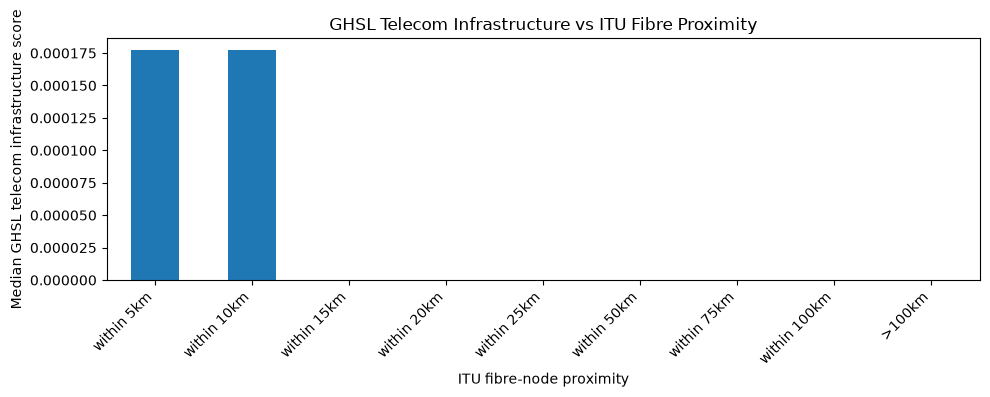

In [43]:

import pandas as pd
from scipy.stats import spearmanr
import matplotlib.pyplot as plt

# ITU categories ordered from nearest to farthest
proximity_order = [
    "within 5km",
    "within 10km",
    "within 15km",
    "within 20km",
    "within 25km",
    "within 50km",
    "within 75km",
    "within 100km",
    ">100km"
]

# Assign ordinal proximity ranks (not actual distances)
rank_map = {
    category: rank
    for rank, category in enumerate(proximity_order, start=1)
}

df_compare["fibre_rank"] = df_compare["proximity"].map(rank_map)

assert df_compare["fibre_rank"].notna().all(), \
    "Some ITU categories were not recognised."

# Summarise GHSL telecom scores by fibre category
summary = (
    df_compare.groupby("proximity", observed=True)
    ["IN_CIS_TEL_2020"]
    .agg(["count", "median", "mean"])
    .reindex(proximity_order)
)

display(summary)

# Spearman rank correlation
rho, p_value = spearmanr(
    df_compare["IN_CIS_TEL_2020"],
    df_compare["fibre_rank"]
)

print(f"Spearman rho: {rho:.4f}")
print(f"P-value: {p_value:.4g}")

# Visualise the median telecom score by category
summary["median"].plot(
    kind="bar",
    figsize=(10, 4)
)

plt.xlabel("ITU fibre-node proximity")
plt.ylabel("Median GHSL telecom infrastructure score")
plt.title("GHSL Telecom Infrastructure vs ITU Fibre Proximity")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


### Final diagnostic — zero scores

In [44]:

# Examine zero GHSL telecommunications scores

df_compare["ghsl_zero"] = (
    df_compare["IN_CIS_TEL_2020"] == 0
)

zero_summary = (
    df_compare.groupby("proximity")["ghsl_zero"]
    .agg(
        total="count",
        zero_scores="sum",
        zero_percentage=lambda x: 100 * x.mean()
    )
    .reindex(proximity_order)
)

display(zero_summary.round(1))

print(
    "Overall GHSL zero percentage:",
    round(100 * df_compare["ghsl_zero"].mean(), 1),
    "%"
)


,total,zero_scores,zero_percentage
proximity,,,
within 5km,1005,430,42.8
within 10km,138,59,42.8
within 15km,143,74,51.7
within 20km,126,76,60.3
within 25km,127,84,66.1
within 50km,331,233,70.4
within 75km,119,80,67.2
within 100km,51,35,68.6
>100km,132,103,78.0


Overall GHSL zero percentage: 54.1 %


### GHSL–ITU Telecommunications Predictor Feasibility Assessment

The GHSL telecommunications infrastructure index and ITU fibre-node proximity data were successfully integrated for all 2,172 African urban centres, with no missing observations.

Spearman's rank correlation indicated a statistically significant but relatively weak negative association (ρ = −0.2602, p = 6.13 × 10⁻³⁵). Furthermore, 54.1% of urban centres recorded a zero GHSL telecommunications score, including 42.8% of centres located within 5 km of a reported fibre node.

These findings suggest that the indicators provide complementary information about telecommunications infrastructure coverage and proximity to terrestrial fibre networks. Both are therefore retained as candidate predictors, subject to subsequent feature selection and model validation.

**Decision: Retain both candidate predictors. Feasibility assessment completed.**

### PeeringDB data feasibility test

PeeringDB API — Kenya Facility Data Feasibility Test

This preliminary test evaluates the accessibility, completeness, and suitability of PeeringDB facility data for integration with the GHSL African urban-centre dataset. Using Kenya as a pilot, we retrieve facility records through the PeeringDB REST API and assess the availability of geographic coordinates and relevant infrastructure attributes. The results will inform whether PeeringDB can provide a reliable supplementary indicator of existing digital interconnection infrastructure across Africa.


In [45]:

import requests
import pandas as pd

url = "https://www.peeringdb.com/api/fac"

response = requests.get(
    url,
    params={"country": "KE"},
    timeout=30
)
response.raise_for_status()

facilities_ke = pd.DataFrame(response.json()["data"])

print("Total Kenyan facilities:", len(facilities_ke))

print(
    "Facilities with coordinates:",
    facilities_ke[["latitude", "longitude"]]
    .notna()
    .all(axis=1)
    .sum()
)

print(
    "Facilities without coordinates:",
    (~facilities_ke[["latitude", "longitude"]]
     .notna()
     .all(axis=1))
    .sum()
)

display(
    facilities_ke[
        ["name", "city", "country",
         "latitude", "longitude",
         "net_count", "ix_count"]
    ].head(15)
)


Total Kenyan facilities: 14
Facilities with coordinates: 11
Facilities without coordinates: 3


,name,city,country,latitude,longitude,net_count,ix_count
0,SEACOM Mombasa CLS,Mombasa,KE,NaN,NaN,31,0
1,"Africa Data Centres, Nairobi NBO1, Kenya",Nairobi,KE,-1.340140,36.896534,130,4
2,SimbaNET Nairobi,Gateway Business Park,KE,-1.325805,36.849609,2,0
3,icolo.io Mombasa One (MBA1),Miritini,KE,-4.007737,39.590389,96,3
4,Africa Digital Data Center - Thika,Thika,KE,NaN,NaN,2,0
5,icolo.io Nairobi One (NBO1),Karen,KE,-1.350080,36.749228,62,4
6,Telkom - Milimani Data Center - Nairobi,Nairobi,KE,-1.290173,36.805290,2,0
7,Telkom - Telephone House - Mombasa,Mombasa,KE,-4.060807,39.657172,9,0
8,Telkom - Telephone House - Nairobi,Nairobi,KE,-1.280859,36.817712,1,0
9,PAIX Nairobi,Nairobi,KE,-1.299937,36.813223,41,3


### PeeringDB — Africa-Wide Facility Coverage Assessment

This assessment evaluates the geographic coverage and coordinate completeness of PeeringDB facility records across Africa. The objective is to determine whether the dataset is suitable for spatial integration with the 2,172 GHSL urban centres and for characterizing existing digital interconnection infrastructure.

In [46]:

# Retrieve PeeringDB facilities and assess Africa-wide coverage

response = requests.get(
    "https://www.peeringdb.com/api/fac",
    params={"region_continent": "Africa"},
    timeout=60
)
response.raise_for_status()

facilities_africa = pd.DataFrame(response.json()["data"])

# Verify geographic scope
print("Returned continental regions:")
print(facilities_africa["region_continent"].value_counts(dropna=False))

# Coordinate completeness
has_coords = facilities_africa[
    ["latitude", "longitude"]
].notna().all(axis=1)

print("\nTotal facilities:", len(facilities_africa))
print("Facilities with coordinates:", has_coords.sum())
print("Facilities without coordinates:", (~has_coords).sum())
print("Coordinate completeness (%):",
      round(100 * has_coords.mean(), 1))

print("\nCountries represented:",
      facilities_africa["country"].nunique())

print("\nTop 15 countries by facility count:")
display(
    facilities_africa["country"]
    .value_counts()
    .head(15)
    .rename_axis("Country")
    .reset_index(name="Facilities")
)


Returned continental regions:
region_continent
Africa    181
Name: count, dtype: int64

Total facilities: 181
Facilities with coordinates: 137
Facilities without coordinates: 44
Coordinate completeness (%): 75.7

Countries represented: 40

Top 15 countries by facility count:


,Country,Facilities
0,ZA,28
1,NG,18
2,TZ,15
3,KE,14
4,AO,8
5,CM,7
6,GH,7
7,MZ,7
8,MU,7
9,RW,5


### save the dataset

In [47]:

from pathlib import Path

raw_dir = Path("../data/raw")
interim_dir = Path("../data/interim")

raw_dir.mkdir(parents=True, exist_ok=True)
interim_dir.mkdir(parents=True, exist_ok=True)

# Preserve all retrieved records
facilities_africa.to_csv(
    raw_dir / "peeringdb_africa_facilities.csv",
    index=False
)

# Create a georeferenced subset
facilities_geo = facilities_africa.loc[
    facilities_africa[["latitude", "longitude"]]
    .notna().all(axis=1)
].copy()

facilities_geo.to_csv(
    interim_dir / "peeringdb_africa_georeferenced.csv",
    index=False
)

print("All facilities:", len(facilities_africa))
print("Georeferenced facilities:", len(facilities_geo))
print("Unique facility IDs:", facilities_geo["id"].nunique())
print("Files saved successfully.")


All facilities: 181
Georeferenced facilities: 137
Unique facility IDs: 137
Files saved successfully.


### PeeringDB–GHSL Spatial Integration

This analysis spatially links georeferenced PeeringDB facilities to GHSL urban-centre polygons across Africa. Facilities located within urban-centre boundaries are assigned to their corresponding GHSL IDs. Facilities outside these boundaries will be examined separately using nearest-centre distances. The resulting facility indicators will support external interpretation of the machine-learning clusters.

In [48]:

import geopandas as gpd
from pathlib import Path

raw_dir = Path("../data/raw")

ssa_file = raw_dir / "GHS_UCDB_REGION_SUB_SAHARAN_AFRICA_R2024A.gpkg"
north_file = raw_dir / "GHS_UCDB_REGION_NORTHERN_AFRICA_AND_WESTERN_ASIA_R2024A.gpkg"

# Inspect available layers before loading
print("Sub-Saharan Africa layers:")
print(gpd.list_layers(ssa_file))

print("\nNorthern Africa and Western Asia layers:")
print(gpd.list_layers(north_file))


Sub-Saharan Africa layers:
                                                 name geometry_type
0   GHSL_UCDB_THEME_GENERAL_CHARACTERISTICS_GLOBE_...  MultiPolygon
1                   GHSL_UCDB_THEME_GHSL_GLOBE_R2024A  MultiPolygon
2                GHSL_UCDB_THEME_CLIMATE_GLOBE_R2024A  MultiPolygon
3              GHSL_UCDB_THEME_EMISSIONS_GLOBE_R2024A  MultiPolygon
4               GHSL_UCDB_THEME_EXPOSURE_GLOBE_R2024A  MultiPolygon
5              GHSL_UCDB_THEME_GEOGRAPHY_GLOBE_R2024A  MultiPolygon
6              GHSL_UCDB_THEME_GREENNESS_GLOBE_R2024A  MultiPolygon
7            GHSL_UCDB_THEME_HAZARD_RISK_GLOBE_R2024A  MultiPolygon
8                 GHSL_UCDB_THEME_HEALTH_GLOBE_R2024A  MultiPolygon
9        GHSL_UCDB_THEME_INFRASTRUCTURES_GLOBE_R2024A  MultiPolygon
10                  GHSL_UCDB_THEME_LULC_GLOBE_R2024A  MultiPolygon
11       GHSL_UCDB_THEME_NATURAL_SYSTEMS_GLOBE_R2024A  MultiPolygon
12                   GHSL_UCDB_THEME_SDG_GLOBE_R2024A  MultiPolygon
13         GHSL_UCDB_

### Inspect the polygon attributes

In [49]:

# Select the general-characteristics polygon layer
layer_ssa = gpd.list_layers(ssa_file).iloc[0]["name"]
layer_north = gpd.list_layers(north_file).iloc[0]["name"]

# Load both regional datasets
ghsl_ssa = gpd.read_file(ssa_file, layer=layer_ssa)
ghsl_north = gpd.read_file(north_file, layer=layer_north)

print("SSA polygons:", len(ghsl_ssa))
print("Northern Africa + Western Asia polygons:", len(ghsl_north))

print("\nSSA CRS:", ghsl_ssa.crs)
print("Northern region CRS:", ghsl_north.crs)

print("\nAvailable columns:")
print(ghsl_north.columns.tolist())

print("\nFirst five records:")
display(ghsl_north.drop(columns="geometry").head())


SSA polygons: 1658
Northern Africa + Western Asia polygons: 1038

SSA CRS: PROJCS["World_Mollweide",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Mollweide"],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["ESRI","54009"]]
Northern region CRS: PROJCS["World_Mollweide",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Mollweide"],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["ESRI","54009"]]

Available columns:
['ID_UC_G0', 'GC

,ID_UC_G0,GC_UCN_MAI_2025,GC_UCN_LIS_2025,GC_CNT_GAD_2025,GC_CNT_UNN_2025,GC_UCA_KM2_2025,GC_POP_TOT_2025,GC_DEV_WIG_2025,GC_DEV_USR_2025,GC_PLS_SCR_2025,GC_UCB_YOB_2025,GC_UCB_YOD_2025,GC_UCM_CAP
0,45,Dakhla,Dakhla,Western Sahara,Western Sahara,33,180740.47580,NaN,Northern Africa and Western Asia,High,2005,2030,0
1,58,Bechar,Bechar,Algeria,Algeria,30,200687.22400,Lower Middle,Northern Africa and Western Asia,High,1985,2030,0
2,74,Al-Kaf,Al-Kaf,Tunisia,Tunisia,11,50808.68934,Lower Middle,Northern Africa and Western Asia,High,2000,2025,0
3,81,Al Zawiyah,Al Zawiyah; Surman,Libya,Libya,115,210856.64570,Upper Middle,Northern Africa and Western Asia,High,2000,2030,0
4,111,El Geneina,El Geneina,Sudan,Sudan,23,164688.11840,Low income,Northern Africa and Western Asia,High,1975,2030,0


### Extract Northern Africa and combine the polygons

In [50]:

import pandas as pd
import geopandas as gpd

# Northern African countries/territory in our study
north_africa = [
    "Algeria",
    "Egypt",
    "Libya",
    "Morocco",
    "Sudan",
    "Tunisia",
    "Western Sahara"
]

# Extract Northern African urban centres
ghsl_north_africa = ghsl_north[
    ghsl_north["GC_CNT_GAD_2025"].isin(north_africa)
].copy()

# Combine with Sub-Saharan Africa
ghsl_africa = gpd.GeoDataFrame(
    pd.concat(
        [ghsl_ssa, ghsl_north_africa],
        ignore_index=True
    ),
    geometry="geometry",
    crs=ghsl_ssa.crs
)

# Validate
print("Sub-Saharan Africa:", len(ghsl_ssa))
print("Northern Africa:", len(ghsl_north_africa))
print("Total African urban centres:", len(ghsl_africa))
print("Unique GHSL IDs:", ghsl_africa["ID_UC_G0"].nunique())
print("CRS:", ghsl_africa.crs)

assert len(ghsl_north_africa) == 514
assert len(ghsl_africa) == 2172
assert ghsl_africa["ID_UC_G0"].is_unique

print("\nAll validations passed!")


Sub-Saharan Africa: 1658
Northern Africa: 514
Total African urban centres: 2172
Unique GHSL IDs: 2172
CRS: PROJCS["World_Mollweide",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Mollweide"],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["ESRI","54009"]]

All validations passed!


### Spatially match PeeringDB facilities to GHSL urban centres

In [51]:

# Prepare georeferenced PeeringDB facilities
facilities_points = gpd.GeoDataFrame(
    facilities_geo.copy(),
    geometry=gpd.points_from_xy(
        facilities_geo["longitude"],
        facilities_geo["latitude"]
    ),
    crs="EPSG:4326"
)

# Transform facilities to GHSL projection
facilities_points = facilities_points.to_crs(ghsl_africa.crs)

# Keep relevant GHSL attributes
urban_polygons = ghsl_africa[
    ["ID_UC_G0", "GC_UCN_MAI_2025",
     "GC_CNT_GAD_2025", "geometry"]
].copy()

# Spatial join: facility inside urban-centre polygon
facility_matches = gpd.sjoin(
    facilities_points,
    urban_polygons,
    how="left",
    predicate="within"
)

# Summarise matching results
matched = facility_matches["ID_UC_G0"].notna()

print("Total georeferenced facilities:", len(facilities_points))
print("Facilities matched to urban centres:", matched.sum())
print("Facilities outside urban centres:", (~matched).sum())
print(
    "Unique urban centres with facilities:",
    facility_matches.loc[matched, "ID_UC_G0"].nunique()
)

# Inspect facilities outside urban boundaries
display(
    facility_matches.loc[
        ~matched,
        ["name", "city", "country", "latitude", "longitude"]
    ].head(15)
)


Total georeferenced facilities: 137
Facilities matched to urban centres: 113
Facilities outside urban centres: 24
Unique urban centres with facilities: 48


,name,city,country,latitude,longitude
15,Equinix AC1 - Accra,Accra,GH,5.802659,-0.094369
16,SEACOM Mtunzini CLS,Mtunzini,ZA,-28.960238,31.758384
20,xneelo JNB1 (Formerly Hetzner SA),Centurion,ZA,-25.927622,28.140755
30,Beonline 24/7,Groot Drakenstein,ZA,-33.839236,18.972623
49,"Equinix LG1/LG2 – Lagos, Lekki",Lekki,NG,6.449602,3.588328
63,icolo.io Nairobi One (NBO1),Karen,KE,-1.350080,36.749228
66,Teraco Johannesburg Bredell Campus,Johannesburg,ZA,-26.074142,28.278459
71,Government Online Centre,Port Louis,MU,-20.245227,57.491810
86,SIPOPO DATACENTER,Malabo,GQ,3.751458,8.908249
91,"Africa Data Centres, Johannesburg JHB2, South ...",Samrand,ZA,-25.930536,28.138418


### Find the nearest urban centre for unmatched facilities

In [52]:

# Select facilities outside GHSL urban-centre polygons
unmatched = facility_matches[
    facility_matches["ID_UC_G0"].isna()
].copy()

# Remove columns inherited from the first spatial join
unmatched = unmatched.drop(
    columns=[
        "index_right",
        "ID_UC_G0",
        "GC_UCN_MAI_2025",
        "GC_CNT_GAD_2025"
    ],
    errors="ignore"
)

# Match each facility to the nearest urban polygon
nearest = gpd.sjoin_nearest(
    unmatched,
    urban_polygons,
    how="left",
    distance_col="distance_m"
)

nearest["distance_km"] = nearest["distance_m"] / 1000

# Country-code check using GHSL's existing country field
country_codes = {
    "Algeria": "DZ", "Angola": "AO",
    "Benin": "BJ", "Botswana": "BW",
    "Burkina Faso": "BF", "Burundi": "BI",
    "Cameroon": "CM", "Cabo Verde": "CV",
    "Central African Republic": "CF", "Chad": "TD",
    "Comoros": "KM", "Congo": "CG",
    "Democratic Republic of the Congo": "CD",
    "Djibouti": "DJ", "Egypt": "EG",
    "Equatorial Guinea": "GQ", "Eritrea": "ER",
    "Eswatini": "SZ", "Ethiopia": "ET",
    "Gabon": "GA", "Gambia": "GM",
    "Ghana": "GH", "Guinea": "GN",
    "Guinea-Bissau": "GW", "Ivory Coast": "CI",
    "Kenya": "KE", "Lesotho": "LS",
    "Liberia": "LR", "Libya": "LY",
    "Madagascar": "MG", "Malawi": "MW",
    "Mali": "ML", "Mauritania": "MR",
    "Mauritius": "MU", "Morocco": "MA",
    "Mozambique": "MZ", "Namibia": "NA",
    "Niger": "NE", "Nigeria": "NG",
    "Rwanda": "RW", "Senegal": "SN",
    "Seychelles": "SC", "Sierra Leone": "SL",
    "Somalia": "SO", "South Africa": "ZA",
    "South Sudan": "SS", "Sudan": "SD",
    "Tanzania": "TZ", "Togo": "TG",
    "Tunisia": "TN", "Uganda": "UG",
    "Zambia": "ZM", "Zimbabwe": "ZW"
}

nearest["nearest_country_code"] = (
    nearest["GC_CNT_GAD_2025"].map(country_codes)
)

nearest["same_country"] = (
    nearest["country"] == nearest["nearest_country_code"]
)

# Show all unmatched facilities, sorted by distance
display(
    nearest[
        ["name", "city", "country",
         "GC_UCN_MAI_2025", "GC_CNT_GAD_2025",
         "distance_km", "same_country"]
    ].sort_values("distance_km").round(2)
)


,name,city,country,GC_UCN_MAI_2025,GC_CNT_GAD_2025,distance_km,same_country
66,Teraco Johannesburg Bredell Campus,Johannesburg,ZA,Johannesburg,South Africa,0.05,True
49,"Equinix LG1/LG2 – Lagos, Lekki",Lekki,NG,Lagos,Nigeria,0.19,True
71,Government Online Centre,Port Louis,MU,Port Louis,Mauritius,0.34,True
102,Rogers Capital Data Center,Ebene,MU,Port Louis,Mauritius,0.34,True
118,Equinix AB1 - Abidjan,Grand Bassam,CI,Grand-Bassam,CÃ´te d'Ivoire,0.36,False
164,"Raxio, CIV1, Abidjan, Côte d’Ivoire","Zone Franche, VITIB,",CI,Grand-Bassam,CÃ´te d'Ivoire,0.36,False
167,Datacenter service Abidjan CIV01,Grand Bassam,CI,Grand-Bassam,CÃ´te d'Ivoire,0.36,False
20,xneelo JNB1 (Formerly Hetzner SA),Centurion,ZA,Centurion,South Africa,0.63,True
179,Digital Delta IX - BOFINET,Gaborone,BW,Gaborone,Botswana,0.72,True
91,"Africa Data Centres, Johannesburg JHB2, South ...",Samrand,ZA,Centurion,South Africa,0.98,True


### Correct and review the 24 unmatched facilities


##### PeeringDB Spatial Matching — Country Validation and Assignment Review

This step corrects the Côte d’Ivoire country-name mismatch and evaluates the 24 PeeringDB facilities located outside GHSL urban-centre boundaries. Facilities within 5 km are considered for assignment, while those between 5 and 15 km require individual review. Country consistency and assignment decisions are documented to ensure transparent and reproducible spatial integration.


In [53]:

# Correct the Côte d'Ivoire country-name encoding
nearest.loc[
    nearest["country"] == "CI",
    "nearest_country_code"
] = "CI"

nearest["same_country"] = (
    nearest["country"] == nearest["nearest_country_code"]
)

# Classify proximity-based assignments
def assignment_review(row):
    if not row["same_country"]:
        return "Review country mismatch"
    elif row["distance_km"] <= 5:
        return "Assign - close proximity"
    elif row["distance_km"] <= 15:
        return "Review - 5 to 15 km"
    else:
        return "Leave unmatched"

nearest["assignment_review"] = nearest.apply(
    assignment_review, axis=1
)

print(nearest["assignment_review"].value_counts())

display(
    nearest[
        ["name", "city", "GC_UCN_MAI_2025",
         "distance_km", "same_country",
         "assignment_review"]
    ].sort_values("distance_km").round(2)
)


assignment_review
Assign - close proximity    17
Review - 5 to 15 km          7
Name: count, dtype: int64


,name,city,GC_UCN_MAI_2025,distance_km,same_country,assignment_review
66,Teraco Johannesburg Bredell Campus,Johannesburg,Johannesburg,0.05,True,Assign - close proximity
49,"Equinix LG1/LG2 – Lagos, Lekki",Lekki,Lagos,0.19,True,Assign - close proximity
71,Government Online Centre,Port Louis,Port Louis,0.34,True,Assign - close proximity
102,Rogers Capital Data Center,Ebene,Port Louis,0.34,True,Assign - close proximity
118,Equinix AB1 - Abidjan,Grand Bassam,Grand-Bassam,0.36,True,Assign - close proximity
164,"Raxio, CIV1, Abidjan, Côte d’Ivoire","Zone Franche, VITIB,",Grand-Bassam,0.36,True,Assign - close proximity
167,Datacenter service Abidjan CIV01,Grand Bassam,Grand-Bassam,0.36,True,Assign - close proximity
20,xneelo JNB1 (Formerly Hetzner SA),Centurion,Centurion,0.63,True,Assign - close proximity
179,Digital Delta IX - BOFINET,Gaborone,Gaborone,0.72,True,Assign - close proximity
91,"Africa Data Centres, Johannesburg JHB2, South ...",Samrand,Centurion,0.98,True,Assign - close proximity


### PeeringDB Spatial Integration — Review of Unmatched Facilities

Of the 137 georeferenced PeeringDB facilities across Africa, 113 were successfully matched to GHSL urban-centre polygons, representing 48 unique urban centres. The remaining 24 facilities were assessed using proximity to the nearest GHSL urban centre and country consistency. After correcting the Côte d’Ivoire country-name mismatch, all 24 had consistent country assignments. Seventeen facilities fall within 5 km of their nearest urban centre and are considered strong candidates for assignment, subject to geographic plausibility checks. The remaining seven, located between 5 and 15 km from their nearest urban-centre boundaries, require individual review.

**Next step:** Evaluate the seven facilities using their coordinates, reported locations and geographic context before finalizing assignments. Accepted facilities will then be combined with the original spatial matches and aggregated by GHSL urban-centre ID (`ID_UC_G0`). PeeringDB will serve as an independent reference for interpreting the subsequent clustering results.

### Review the seven remaining facilities

In [54]:


# Step 7: Inspect the seven facilities requiring individual review

review_7 = nearest.loc[
    nearest["assignment_review"] == "Review - 5 to 15 km"
].copy()

columns_to_show = [
    "name", "city", "country",
    "latitude", "longitude",
    "GC_UCN_MAI_2025", "GC_CNT_GAD_2025",
    "distance_km", "same_country"
]

display(
    review_7[columns_to_show]
    .sort_values("distance_km")
    .round({"distance_km": 2})
)

print("Facilities requiring review:", len(review_7))



,name,city,country,latitude,longitude,GC_UCN_MAI_2025,GC_CNT_GAD_2025,distance_km,same_country
15,Equinix AC1 - Accra,Accra,GH,5.802659,-0.094369,Accra,Ghana,5.56,True
151,Dolphin Coast Wireless & Fiber Solutions,Ballito,ZA,-29.535430,31.213872,Tongaat,South Africa,5.98,True
86,SIPOPO DATACENTER,Malabo,GQ,3.751458,8.908249,Malabo,Equatorial Guinea,8.63,True
127,Paratus Armada,Windhoek,NA,-22.414477,17.068081,Windhoek,Namibia,8.79,True
30,Beonline 24/7,Groot Drakenstein,ZA,-33.839236,18.972623,Paarl,South Africa,10.82,True
152,Mauritius Telecom RBDC,Rose Belle,MU,-20.420012,57.609248,Port Louis,Mauritius,11.33,True
16,SEACOM Mtunzini CLS,Mtunzini,ZA,-28.960238,31.758384,Sikhalasenkosi,South Africa,13.62,True


Facilities requiring review: 7


### Document Provisional Facility Assignments

Following the geographic review, two facilities (Equinix AC1 – Accra and Paratus Armada – Windhoek) are considered plausible candidates for assignment, subject to location verification. The remaining five will provisionally remain unmatched pending further verification. These decisions are recorded separately to ensure transparency and reproducibility before finalizing the PeeringDB–GHSL spatial integration.

In [55]:

# Step 8: Record provisional decisions for the seven facilities

proposed_assignments = {
    15: "Assign - verify location",
    151: "Leave unmatched - verify",
    86: "Leave unmatched - verify",
    127: "Assign - verify location",
    30: "Leave unmatched - verify",
    152: "Leave unmatched - verify",
    16: "Leave unmatched - verify"
}

review_7["proposed_decision"] = (
    review_7.index.map(proposed_assignments)
)

display(
    review_7[
        ["name", "city", "GC_UCN_MAI_2025",
         "distance_km", "proposed_decision"]
    ].sort_values("distance_km")
)

print(review_7["proposed_decision"].value_counts())


,name,city,GC_UCN_MAI_2025,distance_km,proposed_decision
15,Equinix AC1 - Accra,Accra,Accra,5.557380,Assign - verify location
151,Dolphin Coast Wireless & Fiber Solutions,Ballito,Tongaat,5.977056,Leave unmatched - verify
86,SIPOPO DATACENTER,Malabo,Malabo,8.628620,Leave unmatched - verify
127,Paratus Armada,Windhoek,Windhoek,8.790490,Assign - verify location
30,Beonline 24/7,Groot Drakenstein,Paarl,10.822343,Leave unmatched - verify
152,Mauritius Telecom RBDC,Rose Belle,Port Louis,11.327353,Leave unmatched - verify
16,SEACOM Mtunzini CLS,Mtunzini,Sikhalasenkosi,13.618078,Leave unmatched - verify


proposed_decision
Leave unmatched - verify    5
Assign - verify location    2
Name: count, dtype: int64


### Verify the two candidate assignments

In [56]:

# Step 9: Inspect the two candidate facilities
candidate_ids = [15, 127]

candidate_details = facilities_africa.loc[
    facilities_africa["id"].isin(candidate_ids)
].copy()

columns = [
    "id", "name", "city", "country",
    "address1", "address2",
    "latitude", "longitude", "notes"
]

available_columns = [
    col for col in columns
    if col in candidate_details.columns
]

display(candidate_details[available_columns])


,id,name,city,country,address1,address2,latitude,longitude,notes


### Correct the facility selection

In [57]:

# Step 9: Retrieve the two candidates using their review indices

candidate_details = review_7.loc[[15, 127]].copy()

columns = [
    "id", "name", "city", "country",
    "address1", "address2",
    "latitude", "longitude", "notes",
    "GC_UCN_MAI_2025", "distance_km"
]

available_columns = [
    col for col in columns
    if col in candidate_details.columns
]

display(candidate_details[available_columns])


,id,name,city,country,address1,address2,latitude,longitude,notes,GC_UCN_MAI_2025,distance_km
15,1965,Equinix AC1 - Accra,Accra,GH,"Plot No 1, Benin Boulevard, Appolonia Industri...","Accra, Ghana",5.802659,-0.094369,,Accra,5.55738
127,12664,Paratus Armada,Windhoek,NA,"H3P9+56G, Windhoek, Namibia",,-22.414477,17.068081,,Windhoek,8.79049


### Inspect addresses of the remaining 5 facilities

In [58]:

# Step 10: Inspect addresses of the five unresolved facilities

unresolved_indices = [151, 86, 30, 152, 16]

unresolved = review_7.loc[unresolved_indices].copy()

address_fields = [
    "id", "name", "city", "country",
    "address1", "address2",
    "latitude", "longitude",
    "GC_UCN_MAI_2025", "distance_km",
    "notes"
]

# Retrieve full PeeringDB details using actual facility IDs
unresolved_details = facilities_africa.loc[
    facilities_africa["id"].isin(unresolved["id"])
].copy()

available = [
    col for col in address_fields
    if col in unresolved_details.columns
]

display(unresolved_details[available])


,id,name,city,country,address1,address2,latitude,longitude,notes
16,2031,SEACOM Mtunzini CLS,Mtunzini,ZA,140 Natures Way,,-28.960238,31.758384,
30,3417,Beonline 24/7,Groot Drakenstein,ZA,7 Canary Row,,-33.839236,18.972623,
86,9041,SIPOPO DATACENTER,Malabo,GQ,Sipopo,,3.751458,8.908249,
151,14016,Dolphin Coast Wireless & Fiber Solutions,Ballito,ZA,82 Zen Dr,,-29.535430,31.213872,
152,14075,Mauritius Telecom RBDC,Rose Belle,MU,Gros Billot,,-20.420012,57.609248,


### Check whether the 5 cities appear as separate urban centres in our GHSL dataset.

In [59]:

# Check whether the reported localities exist in GHSL

localities = [
    "Mtunzini",
    "Groot Drakenstein",
    "Malabo",
    "Ballito",
    "Rose Belle"
]

for locality in localities:
    matches = ghsl_africa[
        ghsl_africa["GC_UCN_MAI_2025"].str.contains(
            locality, case=False, na=False, regex=False
        )
    ]

    print(f"\n{locality}: {len(matches)} GHSL matches")

    if not matches.empty:
        display(matches[
            ["ID_UC_G0", "GC_UCN_MAI_2025",
             "GC_CNT_GAD_2025"]
        ])



Mtunzini: 0 GHSL matches

Groot Drakenstein: 0 GHSL matches

Malabo: 1 GHSL matches


,ID_UC_G0,GC_UCN_MAI_2025,GC_CNT_GAD_2025
17,76,Malabo,Equatorial Guinea



Ballito: 0 GHSL matches

Rose Belle: 0 GHSL matches


### GHSL Urban-Centre Verification and PeeringDB Facility Assignment

A geographic review was conducted to determine whether five PeeringDB facilities located outside GHSL urban-centre boundaries could be assigned to nearby urban centres. Facility coordinates, reported addresses, locality names, and distances to the nearest GHSL polygons were examined. An additional name-based search was performed against the **2,172 African GHSL urban centres**.

**Key findings:**

- **Malabo (Equatorial Guinea)** was confirmed as a GHSL urban centre (`ID_UC_G0 = 76`). SIPOPO DATACENTER, located approximately 8.63 km outside its boundary, remains a provisional candidate for proximity-based assignment.
- **Mtunzini, Groot Drakenstein, Ballito, and Rose Belle** returned no exact locality-name matches in the GHSL dataset. This does not necessarily mean these settlements are absent from GHSL geography; they may be smaller settlements, incorporated into larger agglomerations, or represented under different names.
- The four corresponding facilities will remain unmatched rather than being assigned to geographically nearby but potentially unrelated urban centres. Their original PeeringDB records, addresses, and coordinates will be retained for transparency and reproducibility.

**Methodological decision:** Facility assignments will distinguish between direct point-in-polygon matches, geographically justified proximity-based assignments, and unresolved facilities. The GHSL urban-centre dataset remains the defined unit of analysis, and facilities outside its boundaries will not be assigned solely to maximize coverage.

**Next step:** Finalize and document accepted facility assignments, aggregate facility counts by GHSL urban-centre ID (`ID_UC_G0`), and save the PeeringDB reference dataset for independent interpretation of the subsequent clustering results.

### Finalize Proximity-Based Facility Assignments
This step applies the agreed geographic criteria to the 24 PeeringDB facilities located outside GHSL urban-centre boundaries. We provisionally accept 17 close-proximity matches and two geographically reviewed assignments, while retaining five unresolved facilities for transparency. Assignment methods and statuses are recorded to ensure traceability and reproducibility before integrating the accepted facilities with the 113 direct polygon matches.

In [60]:

# Step 11B: Identify the original point-in-polygon results

import pandas as pd
import geopandas as gpd

candidates = []

for variable_name, obj in list(globals().items()):
    if isinstance(obj, (pd.DataFrame, gpd.GeoDataFrame)):
        if "ID_UC_G0" in obj.columns and "id" in obj.columns:
            candidates.append({
                "variable": variable_name,
                "rows": len(obj),
                "unique_facilities": obj["id"].nunique(),
                "matched_urban_centres": obj["ID_UC_G0"].notna().sum()
            })

display(pd.DataFrame(candidates))


,variable,rows,unique_facilities,matched_urban_centres
0,nearest,24,24,24
1,facility_matches,137,137,113
2,review_7,7,7,7
3,candidate_details,2,2,2
4,unresolved,5,5,5


### Create nearest_final

In [63]:

# Create final proximity-assignment table from existing results
nearest_final = nearest.copy()

# Review indices from our seven-facility assessment
# Two candidate assignments; five remain unresolved
candidate_indices = [15, 127]
unresolved_indices = [16, 30, 86, 151, 152]

# Preserve decisions transparently
nearest_final["assignment_method"] = "proximity"
nearest_final["assignment_status"] = "provisional"

nearest_final.loc[
    nearest_final.index.isin(unresolved_indices),
    "assignment_method"
] = "pending_review"

nearest_final.loc[
    nearest_final.index.isin(unresolved_indices),
    "assignment_status"
] = "unresolved"

# Candidate assignments are provisional, not independently verified
nearest_final.loc[
    nearest_final.index.isin(candidate_indices),
    "assignment_method"
] = "proximity_reviewed"

# Unresolved facilities must not receive a GHSL assignment
nearest_final.loc[
    nearest_final["assignment_status"] == "unresolved",
    "ID_UC_G0"
] = pd.NA

# Validate the decisions
assert len(nearest_final) == 24
assert nearest_final["assignment_status"].eq("provisional").sum() == 19
assert nearest_final["assignment_status"].eq("unresolved").sum() == 5

print("Final proximity review:")
print(nearest_final["assignment_status"].value_counts())

print("\nAssignment methods:")
print(nearest_final["assignment_method"].value_counts())


Final proximity review:
assignment_status
provisional    19
unresolved      5
Name: count, dtype: int64

Assignment methods:
assignment_method
proximity             17
pending_review         5
proximity_reviewed     2
Name: count, dtype: int64


### Combine assignments and save reference datasets

In [64]:

import pandas as pd
from pathlib import Path

# Start with all 137 georeferenced facilities
facility_audit = facility_matches.copy()

# Identify original point-in-polygon matches
direct_mask = facility_audit["ID_UC_G0"].notna()

facility_audit["assignment_method"] = "unmatched"
facility_audit["assignment_status"] = "unresolved"
facility_audit["assignment_distance_km"] = pd.NA

facility_audit.loc[direct_mask, "assignment_method"] = "point_in_polygon"
facility_audit.loc[direct_mask, "assignment_status"] = "direct_match"
facility_audit.loc[direct_mask, "assignment_distance_km"] = 0.0

# Merge reviewed proximity results using actual PeeringDB IDs
review_cols = [
    "id", "ID_UC_G0", "distance_km",
    "assignment_method", "assignment_status"
]

reviewed = nearest_final[review_cols].copy()

# Prevent duplicate columns during merge
reviewed = reviewed.rename(columns={
    "ID_UC_G0": "review_uc_id",
    "distance_km": "review_distance_km",
    "assignment_method": "review_method",
    "assignment_status": "review_status"
})

facility_audit = facility_audit.merge(
    reviewed,
    on="id",
    how="left",
    validate="one_to_one"
)

# Assign only provisionally accepted proximity matches
accepted = (
    facility_audit["assignment_status"].eq("unresolved")
    & facility_audit["review_status"].eq("provisional")
)

facility_audit.loc[accepted, "ID_UC_G0"] = (
    facility_audit.loc[accepted, "review_uc_id"]
)

facility_audit.loc[accepted, "assignment_method"] = (
    facility_audit.loc[accepted, "review_method"]
)

facility_audit.loc[accepted, "assignment_status"] = "provisional"

facility_audit.loc[accepted, "assignment_distance_km"] = (
    facility_audit.loc[accepted, "review_distance_km"]
)

# Preserve unresolved review categories
pending = (
    facility_audit["assignment_status"].eq("unresolved")
    & facility_audit["review_method"].eq("pending_review")
)

facility_audit.loc[pending, "assignment_method"] = "pending_review"

# Validate
assert len(facility_audit) == 137
assert facility_audit["id"].is_unique
assert facility_audit["ID_UC_G0"].notna().sum() == 132

print("Facility assignment summary:")
print(facility_audit["assignment_method"].value_counts())

# Aggregate by GHSL urban-centre ID
facility_counts = (
    facility_audit.loc[
        facility_audit["ID_UC_G0"].notna()
    ]
    .groupby("ID_UC_G0")
    .size()
    .reset_index(name="peeringdb_facility_count")
)

# Retain all African urban centres
urban_reference = ghsl_africa[
    ["ID_UC_G0", "GC_UCN_MAI_2025", "GC_CNT_GAD_2025"]
].copy()

urban_reference = urban_reference.merge(
    facility_counts,
    on="ID_UC_G0",
    how="left",
    validate="one_to_one"
)

urban_reference["peeringdb_facility_count"] = (
    urban_reference["peeringdb_facility_count"]
    .fillna(0)
    .astype(int)
)

urban_reference["peeringdb_observed_presence"] = (
    urban_reference["peeringdb_facility_count"] > 0
).astype(int)

assert len(urban_reference) == 2172
assert urban_reference["ID_UC_G0"].is_unique
assert urban_reference["peeringdb_facility_count"].sum() == 132

# Save outputs
output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

facility_audit.drop(
    columns="geometry", errors="ignore"
).to_csv(
    output_dir / "peeringdb_facility_assignment_audit.csv",
    index=False
)

urban_reference.drop(
    columns="geometry", errors="ignore"
).to_csv(
    output_dir / "peeringdb_urban_centre_reference.csv",
    index=False
)

print("\nAssigned facilities:", facility_counts["peeringdb_facility_count"].sum())
print("Urban centres:", len(urban_reference))
print("Urban centres with observed facilities:",
      urban_reference["peeringdb_observed_presence"].sum())
print("\nFiles saved to:", output_dir)


Facility assignment summary:
assignment_method
point_in_polygon      113
proximity              17
pending_review          5
proximity_reviewed      2
Name: count, dtype: int64

Assigned facilities: 132
Urban centres: 2172
Urban centres with observed facilities: 52

Files saved to: data\processed



### PeeringDB–GHSL Integration: Final Results

PeeringDB facility records were spatially linked to 2,172 African GHSL urban centres using point-in-polygon matching and geographically reviewed proximity assignments. Of 137 georeferenced facilities, 113 were matched directly, 19 received provisional proximity assignments, and five remained unresolved. The resulting dataset contains 132 assigned facilities across 52 urban centres. Facility-level audit records and urban-centre reference data were saved to `data/processed`.

PeeringDB will serve as an independent reference for interpreting clustering results, rather than an input to the initial clustering models. Unmatched urban centres must not be interpreted as lacking digital infrastructure.


### DDD

In [65]:

from pathlib import Path

print("Current working directory:", Path.cwd().resolve())
print("Output directory used:", output_dir.resolve())

print("\nPeeringDB files found:")
for file in Path.cwd().rglob("*peeringdb*.csv"):
    print(file.resolve())


Current working directory: D:\Purity\GitHub-Repository\africa-ai-readiness-investment-intelligence\notebooks
Output directory used: D:\Purity\GitHub-Repository\africa-ai-readiness-investment-intelligence\notebooks\data\processed

PeeringDB files found:
D:\Purity\GitHub-Repository\africa-ai-readiness-investment-intelligence\notebooks\data\processed\peeringdb_facility_assignment_audit.csv
D:\Purity\GitHub-Repository\africa-ai-readiness-investment-intelligence\notebooks\data\processed\peeringdb_urban_centre_reference.csv


In [66]:

from pathlib import Path
import shutil

# Project root is one level above the notebooks folder
project_root = Path.cwd().parent

source_dir = Path.cwd() / "data" / "processed"
target_dir = project_root / "data" / "processed"

target_dir.mkdir(parents=True, exist_ok=True)

files_to_move = [
    "peeringdb_facility_assignment_audit.csv",
    "peeringdb_urban_centre_reference.csv"
]

for filename in files_to_move:
    source = source_dir / filename
    target = target_dir / filename

    if not source.exists():
        raise FileNotFoundError(f"Missing source: {source}")

    if target.exists():
        raise FileExistsError(f"Destination already exists: {target}")

    shutil.move(str(source), str(target))
    print(f"Moved successfully: {target}")

# Update output directory for future saves
output_dir = target_dir

print("\nCorrect output directory:", output_dir)


Moved successfully: d:\Purity\GitHub-Repository\africa-ai-readiness-investment-intelligence\data\processed\peeringdb_facility_assignment_audit.csv
Moved successfully: d:\Purity\GitHub-Repository\africa-ai-readiness-investment-intelligence\data\processed\peeringdb_urban_centre_reference.csv

Correct output directory: d:\Purity\GitHub-Repository\africa-ai-readiness-investment-intelligence\data\processed


### look for the Master GHSL 2172 urban centres dataset / file

In [67]:
import pandas as pd
import geopandas as gpd

for name, obj in list(globals().items()):
    if isinstance(obj, (pd.DataFrame, gpd.GeoDataFrame)):
        if "ID_UC_G0" in obj.columns:
            print(
                f"{name}: {len(obj)} rows, "
                f"{obj['ID_UC_G0'].nunique()} unique urban centres, "
                f"{len(obj.columns)} columns"
            )

df_preview: 5 rows, 5 unique urban centres, 13 columns
ssa: 1658 rows, 1658 unique urban centres, 13 columns
north_west: 1038 rows, 1038 unique urban centres, 13 columns
africa_cities: 2172 rows, 2172 unique urban centres, 13 columns
preview: 5 rows, 5 unique urban centres, 28 columns
ids: 1658 rows, 1658 unique urban centres, 1 columns
df_analytical: 2172 rows, 2172 unique urban centres, 24 columns
df: 11422 rows, 11422 unique urban centres, 3 columns
df_sheet: 2172 rows, 2172 unique urban centres, 3 columns
df_check: 3 rows, 3 unique urban centres, 13 columns
matches: 0 rows, 0 unique urban centres, 14 columns
df_coordinates: 11422 rows, 11422 unique urban centres, 3 columns
df_itu: 2172 rows, 2172 unique urban centres, 3 columns
df_names: 5 rows, 5 unique urban centres, 13 columns
nearest: 24 rows, 16 unique urban centres, 49 columns
df_pilot: 5 rows, 5 unique urban centres, 5 columns
df_pilot2: 10 rows, 10 unique urban centres, 5 columns
df_candidates: 2172 rows, 2172 unique urban 

### Check the two candidate datasets

In [68]:
for name in ["africa_cities", "df_analytical"]:
    dataset = globals()[name]

    print(f"\n{name}")
    print(f"Shape: {dataset.shape}")
    print(f"Unique urban centres: {dataset['ID_UC_G0'].nunique()}")
    print("\nColumns:")
    print(dataset.columns.tolist())


africa_cities
Shape: (2172, 13)
Unique urban centres: 2172

Columns:
['ID_UC_G0', 'GC_UCN_MAI_2025', 'GC_UCN_LIS_2025', 'GC_CNT_GAD_2025', 'GC_CNT_UNN_2025', 'GC_UCA_KM2_2025', 'GC_POP_TOT_2025', 'GC_DEV_WIG_2025', 'GC_DEV_USR_2025', 'GC_PLS_SCR_2025', 'GC_UCB_YOB_2025', 'GC_UCB_YOD_2025', 'GC_UCM_CAP']

df_analytical
Shape: (2172, 24)
Unique urban centres: 2172

Columns:
['ID_UC_G0', 'GC_UCN_MAI_2025', 'GC_UCN_LIS_2025', 'GC_CNT_GAD_2025', 'GC_CNT_UNN_2025', 'GC_UCA_KM2_2025', 'GC_POP_TOT_2025', 'GC_DEV_WIG_2025', 'GC_DEV_USR_2025', 'GC_PLS_SCR_2025', 'GC_UCB_YOB_2025', 'GC_UCB_YOD_2025', 'GC_UCM_CAP', 'GH_POP_TOT_2025', 'IN_CIS_ENE_2020', 'IN_CIS_TRA_2020', 'IN_CIS_WAT_2020', 'IN_CIS_TEL_2020', 'IN_CIS_EDU_2020', 'IN_ROA_DEN_2024', 'SC_GDP_AVG_2020', 'SC_SEC_SYT_2020', 'CL_B01_CUR_2010', 'CL_REN_PVO_2020']


### Save the GHSL Urban-Centre Analytical Dataset

In [70]:
from pathlib import Path

# Project root (notebooks are one level below)
PROJECT_ROOT = Path.cwd().parent
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Validate before exporting
assert len(df_analytical) == 2172
assert df_analytical["ID_UC_G0"].nunique() == 2172
assert df_analytical["ID_UC_G0"].notna().all()

# Save the analytical master dataset
output_file = PROCESSED_DIR / "africa_ghsl_urban_centres_2172.csv"

df_analytical.to_csv(output_file, index=False)

print("Saved:", output_file.resolve())
print("Shape:", df_analytical.shape)

Saved: D:\Purity\GitHub-Repository\africa-ai-readiness-investment-intelligence\data\processed\africa_ghsl_urban_centres_2172.csv
Shape: (2172, 24)
